# Beyond the Normal: Using Skewness and Kurtosis to Model House Prices

## Data

This data is a random selection of 1,460 of 2,930 houses sold in Ames, Iowa, from 2006 to 2010. It was compiled by De Cock (2011), who removed non-residential\* and repeat sales† from a set of 3,970 property sales recorded by local government. It serves as the basis for the *House Prices* Kaggle competition.

\* For example: garages, condos, storage areas.
† For houses with multiple sales recorded in the period, only the most recent was included.

First, we check for mistakes and outliers:

We will use the GnrLivArea (total indoor )

Fit: SalePrice = 18,569 + 107.1 × GrLivArea,  R² = 0.502,  σ = 56,073


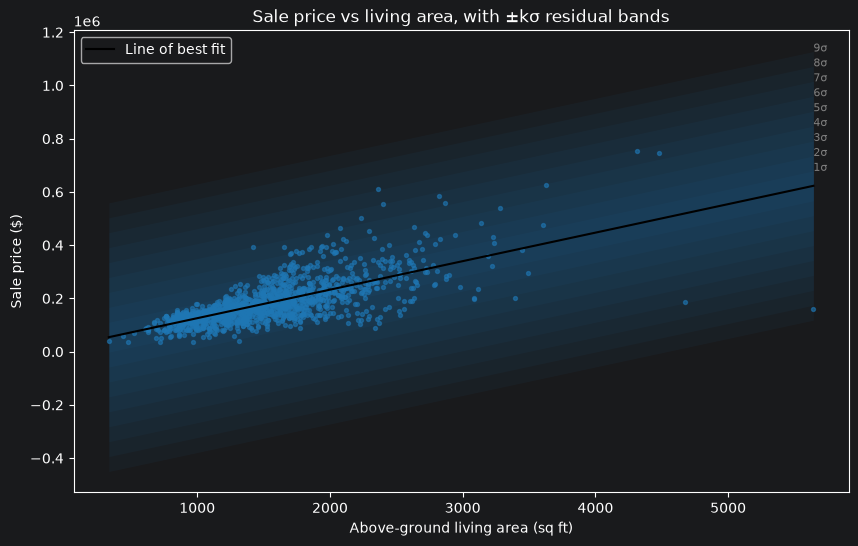

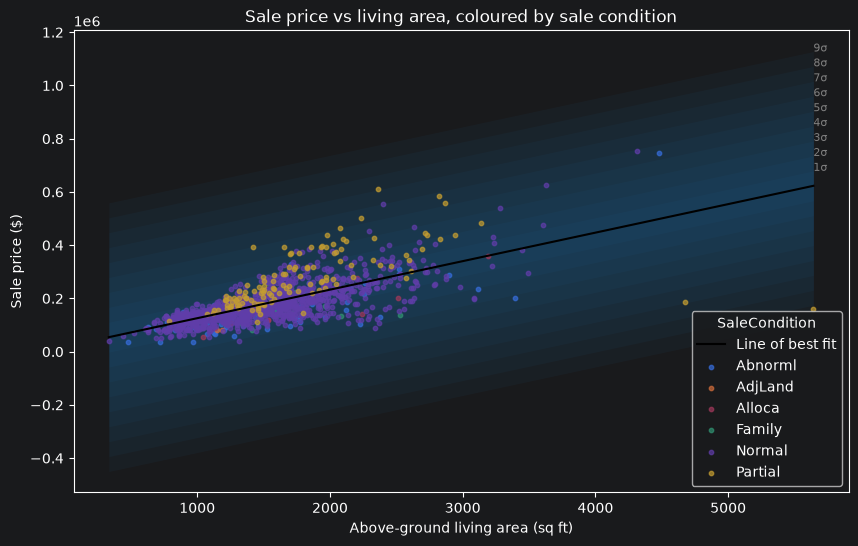

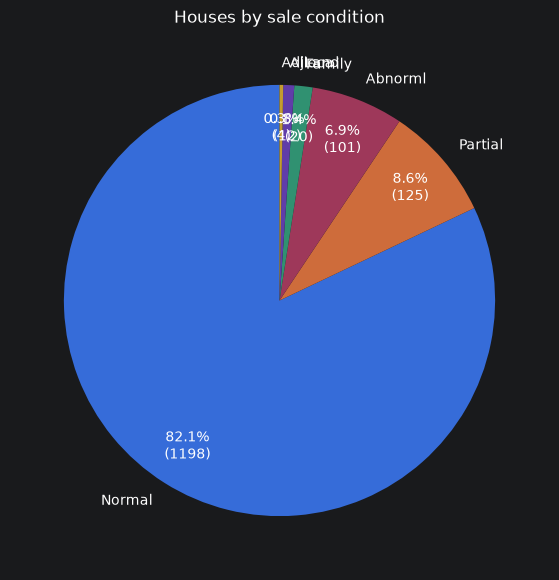

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

train = pd.read_csv("../data/train.csv")
x = train["GrLivArea"].values.astype(float)
y = train["SalePrice"].values.astype(float)

# Fit OLS: SalePrice = b0 + b1 * GrLivArea
ols = sm.OLS(y, sm.add_constant(x)).fit()
b0, b1 = ols.params
sigma = np.sqrt(ols.scale)          # residual standard deviation
k_max = int(np.ceil(np.abs(ols.resid).max() / sigma))   # bands needed to cover every point
print(f"Fit: SalePrice = {b0:,.0f} + {b1:,.1f} × GrLivArea,  R² = {ols.rsquared:.3f},  σ = {sigma:,.0f}")

xs = np.linspace(x.min(), x.max(), 200)
line = b0 + b1 * xs

def plot_bands(ax):
    """Draw the line of best fit and ±kσ bands, widest first so narrower ones sit on top."""
    for k in range(k_max, 0, -1):
        ax.fill_between(xs, line - k * sigma, line + k * sigma,
                        color="tab:blue", alpha=0.06, linewidth=0)
        ax.annotate(f"{k}σ", (xs[-1], line[-1] + k * sigma), fontsize=8, color="grey")
    ax.plot(xs, line, color="black", linewidth=1.5, label="Line of best fit")
    ax.set_xlabel("Above-ground living area (sq ft)")
    ax.set_ylabel("Sale price ($)")

# Plot 1: all points one colour
fig, ax = plt.subplots(figsize=(10, 6))
plot_bands(ax)
ax.scatter(x, y, s=8, alpha=0.6, color="tab:blue")
ax.set_title("Sale price vs living area, with ±kσ residual bands")
ax.legend(); plt.show()

# Plot 2: coloured by sale type
fig, ax = plt.subplots(figsize=(10, 6))
plot_bands(ax)
for condition, group in train.groupby("SaleCondition"):
    ax.scatter(group["GrLivArea"], group["SalePrice"], s=10, alpha=0.7, label=condition)
ax.set_title("Sale price vs living area, coloured by sale condition")
ax.legend(title="SaleCondition"); plt.show()
counts = train["SaleCondition"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(counts, labels=counts.index,
       autopct=lambda p: f"{p:.1f}%\n({p * counts.sum() / 100:.0f})",
       startangle=90, pctdistance=0.8)
ax.set_title("Houses by sale condition")
plt.show()

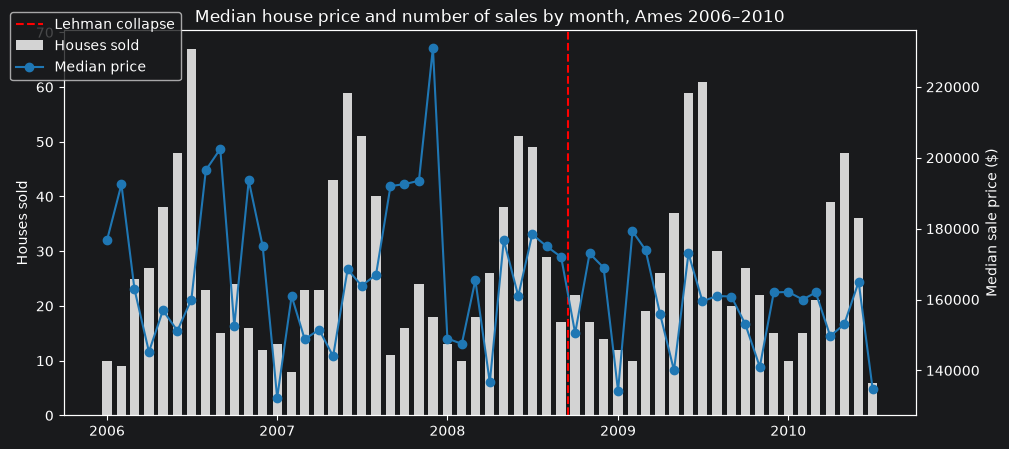

In [6]:
import matplotlib.pyplot as plt

monthly = (train.groupby(["YrSold", "MoSold"])["SalePrice"]
                .agg(median_price="median", houses_sold="count")
                .reset_index())
monthly["date"] = pd.to_datetime(dict(year=monthly["YrSold"], month=monthly["MoSold"], day=1))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(monthly["date"], monthly["houses_sold"], width=20, color="lightgrey", label="Houses sold")
ax1.set_ylabel("Houses sold")

ax2 = ax1.twinx()
ax2.plot(monthly["date"], monthly["median_price"], color="tab:blue", marker="o", label="Median price")
ax2.set_ylabel("Median sale price ($)")

ax1.axvline(pd.Timestamp("2008-09-15"), color="red", linestyle="--", label="Lehman collapse")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.93))
ax1.set_title("Median house price and number of sales by month, Ames 2006–2010")
plt.show()

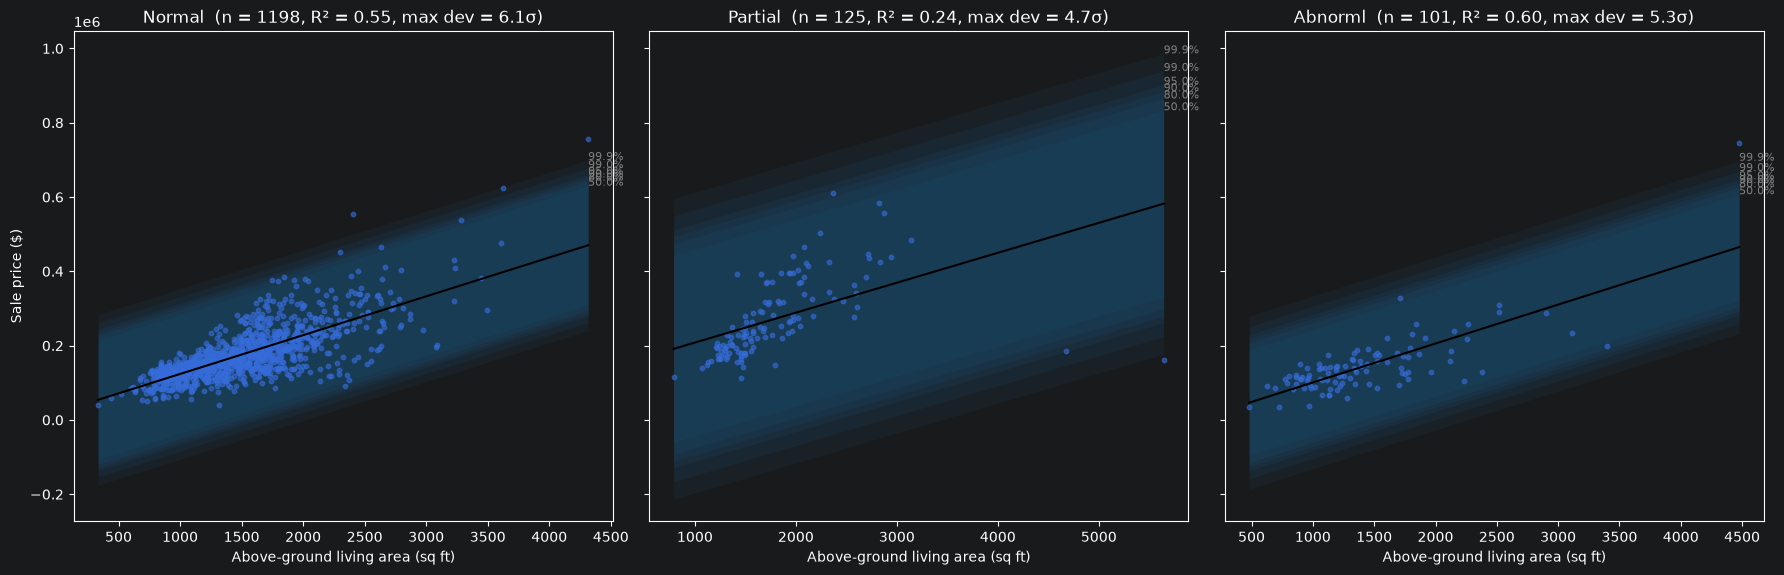

c (σ)                all inside?               
condition Abnorml Normal Partial     Abnorml Normal Partial
p                                                          
0.500         2.7   3.44    2.77       False  False   False
0.800        3.06   3.74    3.12       False  False   False
0.900        3.28   3.92    3.34       False  False   False
0.950        3.48   4.09    3.53       False  False   False
0.990        3.89   4.46    3.94       False  False   False
0.999        4.42   4.93    4.47       False  False   False

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm

probs = [0.50, 0.80, 0.90, 0.95, 0.99, 0.999]
conditions = ["Normal", "Partial", "Abnorml"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
summary = []

for ax, cond in zip(axes, conditions):
    g = train[train["SaleCondition"] == cond]
    x = g["GrLivArea"].values.astype(float)
    y = g["SalePrice"].values.astype(float)
    n = len(g)

    ols = sm.OLS(y, sm.add_constant(x)).fit()
    b0, b1 = ols.params
    sigma = np.sqrt(ols.scale)
    xs = np.linspace(x.min(), x.max(), 200)
    line = b0 + b1 * xs
    max_dev = np.abs(ols.resid).max() / sigma

    for p in reversed(probs):                       # widest band first
        c = norm.ppf((1 + p ** (1 / n)) / 2)
        ax.fill_between(xs, line - c * sigma, line + c * sigma,
                        color="tab:blue", alpha=0.08, linewidth=0)
        ax.annotate(f"{p:.1%}", (xs[-1], line[-1] + c * sigma), fontsize=8, color="grey")
        summary.append({"condition": cond, "n": n, "p": p, "c (σ)": round(c, 2),
                        "all inside?": max_dev <= c})

    ax.scatter(x, y, s=10, alpha=0.6)
    ax.plot(xs, line, color="black", linewidth=1.5)
    ax.set_title(f"{cond}  (n = {n}, R² = {ols.rsquared:.2f}, max dev = {max_dev:.1f}σ)")
    ax.set_xlabel("Above-ground living area (sq ft)")

axes[0].set_ylabel("Sale price ($)")
plt.tight_layout(); plt.show()

pd.DataFrame(summary).pivot(index="p", columns="condition", values=["c (σ)", "all inside?"])

,Id,GrLivArea,SalePrice,Neighborhood,YearBuilt,YrSold
523,524,4676,184750,Edwards,2007,2007
1298,1299,5642,160000,Edwards,2008,2008


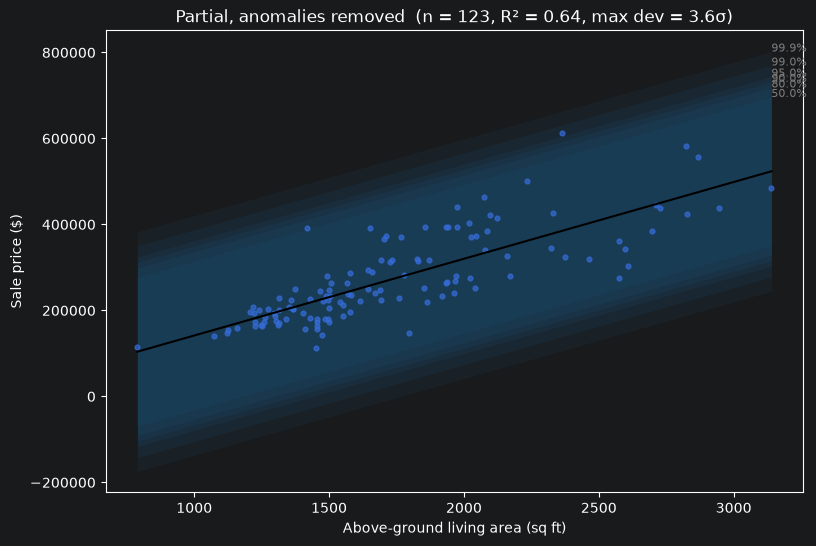

In [10]:
partial = train[train["SaleCondition"] == "Partial"]
anomalous = (partial["GrLivArea"] > 4000) & (partial["SalePrice"] < 300_000)
display(partial.loc[anomalous, ["Id", "GrLivArea", "SalePrice", "Neighborhood", "YearBuilt", "YrSold"]])
partial = partial[~anomalous]

x = partial["GrLivArea"].values.astype(float)
y = partial["SalePrice"].values.astype(float)
n = len(partial)
ols = sm.OLS(y, sm.add_constant(x)).fit()
b0, b1 = ols.params
sigma = np.sqrt(ols.scale)
xs = np.linspace(x.min(), x.max(), 200)
line = b0 + b1 * xs
max_dev = np.abs(ols.resid).max() / sigma

fig, ax = plt.subplots(figsize=(9, 6))
for p in reversed(probs):
    c = norm.ppf((1 + p ** (1 / n)) / 2)
    ax.fill_between(xs, line - c * sigma, line + c * sigma, color="tab:blue", alpha=0.08, linewidth=0)
    ax.annotate(f"{p:.1%}", (xs[-1], line[-1] + c * sigma), fontsize=8, color="grey")
ax.scatter(x, y, s=12, alpha=0.7)
ax.plot(xs, line, color="black", linewidth=1.5)
ax.set_title(f"Partial, anomalies removed  (n = {n}, R² = {ols.rsquared:.2f}, max dev = {max_dev:.1f}σ)")
ax.set_xlabel("Above-ground living area (sq ft)"); ax.set_ylabel("Sale price ($)")
plt.show()

Full-sample OLS slope: $178.5 per sq ft  (n = 123)


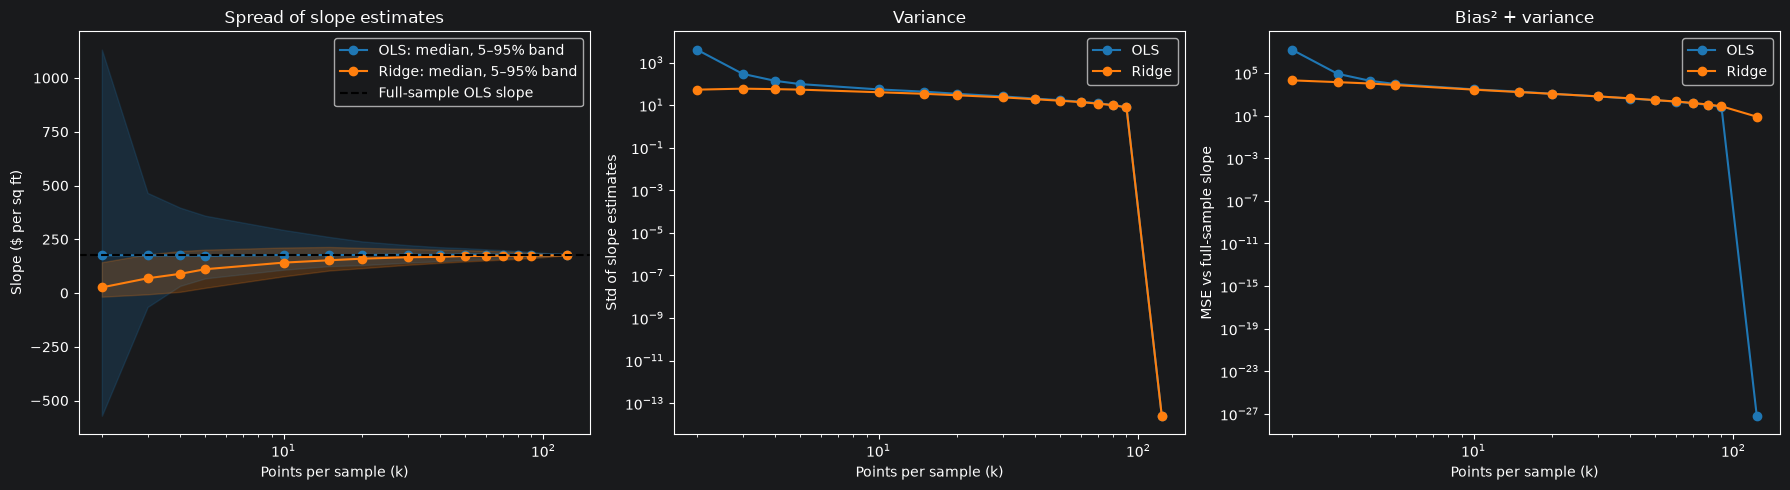

median            std               mse         
method    OLS  Ridge     OLS Ridge         OLS    Ridge
k                                                      
2       176.0   26.3  4022.0  53.1  16176762.0  21096.3
3       175.0   68.6   293.9  59.1     86557.9  14271.5
4       175.7   89.2   137.8  56.2     19156.7  10665.7
5       173.7  110.8    96.9  53.3      9527.6   7648.7
10      176.8  141.5    54.6  40.1      3017.6   2826.9
15      176.6  152.4    42.7  33.9      1838.5   1663.7
20      177.0  159.8    33.9  28.9      1150.1   1149.4
30      178.1  166.4    25.7  23.2       661.3    657.1
40      177.1  168.4    20.2  18.9       409.3    436.4
50      179.2  172.5    17.0  16.0       290.7    290.9
60      178.2  172.4    14.5  13.8       211.3    219.4
70      178.7  173.7    12.1  11.7       147.5    156.1
80      178.6  174.3    10.2   9.9       104.5    113.5
90      178.1  174.2     8.0   7.7        63.9     77.4
123     178.5  175.6     0.0   0.0         0.0      8.2

In [11]:
rng = np.random.default_rng(42)          # fixed seed so results are reproducible
n_all = len(partial)
ks = [2, 3, 4, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, n_all]
n_draws = 2000
lam = 2.0                                 # ridge penalty (in standardised units)

# Standardise so the ridge penalty doesn't depend on units (sq ft vs $)
xp = partial["GrLivArea"].values.astype(float)
yp = partial["SalePrice"].values.astype(float)
sx, sy = xp.std(), yp.std()
zx = (xp - xp.mean()) / sx
zy = (yp - yp.mean()) / sy
to_dollars = sy / sx                      # converts a standardised slope back to $ per sq ft

full_slope = (zx @ zy) / (zx @ zx) * to_dollars
print(f"Full-sample OLS slope: ${full_slope:,.1f} per sq ft  (n = {n_all})")

rows = []
for k in ks:
    # n_draws random subsets of size k, all at once: shape (n_draws, k)
    idx = np.array([rng.choice(n_all, size=k, replace=False) for _ in range(n_draws)])
    X, Y = zx[idx], zy[idx]
    Xc = X - X.mean(axis=1, keepdims=True)
    Yc = Y - Y.mean(axis=1, keepdims=True)
    Sxx = (Xc ** 2).sum(axis=1)
    Sxy = (Xc * Yc).sum(axis=1)

    with np.errstate(divide="ignore", invalid="ignore"):
        ols_slopes = Sxy / Sxx * to_dollars           # undefined if all k points share one x
    ridge_slopes = Sxy / (Sxx + lam) * to_dollars
    ok = np.isfinite(ols_slopes)

    for method, s in [("OLS", ols_slopes[ok]), ("Ridge", ridge_slopes[ok])]:
        rows.append({"k": k, "method": method,
                     "p5": np.percentile(s, 5), "median": np.median(s), "p95": np.percentile(s, 95),
                     "std": s.std(), "mse": np.mean((s - full_slope) ** 2)})

res = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for method, colour in [("OLS", "tab:blue"), ("Ridge", "tab:orange")]:
    r = res[res["method"] == method]
    axes[0].fill_between(r["k"], r["p5"], r["p95"], color=colour, alpha=0.2)
    axes[0].plot(r["k"], r["median"], color=colour, marker="o", label=f"{method}: median, 5–95% band")
    axes[1].plot(r["k"], r["std"], color=colour, marker="o", label=method)
    axes[2].plot(r["k"], r["mse"], color=colour, marker="o", label=method)

axes[0].axhline(full_slope, color="black", linestyle="--", label="Full-sample OLS slope")
axes[0].set_ylabel("Slope ($ per sq ft)")
axes[0].set_title("Spread of slope estimates")
axes[1].set_yscale("log"); axes[1].set_ylabel("Std of slope estimates"); axes[1].set_title("Variance")
axes[2].set_yscale("log"); axes[2].set_ylabel("MSE vs full-sample slope"); axes[2].set_title("Bias² + variance")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("Points per sample (k)"); ax.legend()
plt.tight_layout(); plt.show()

res.pivot(index="k", columns="method", values=["median", "std", "mse"]).round(1)

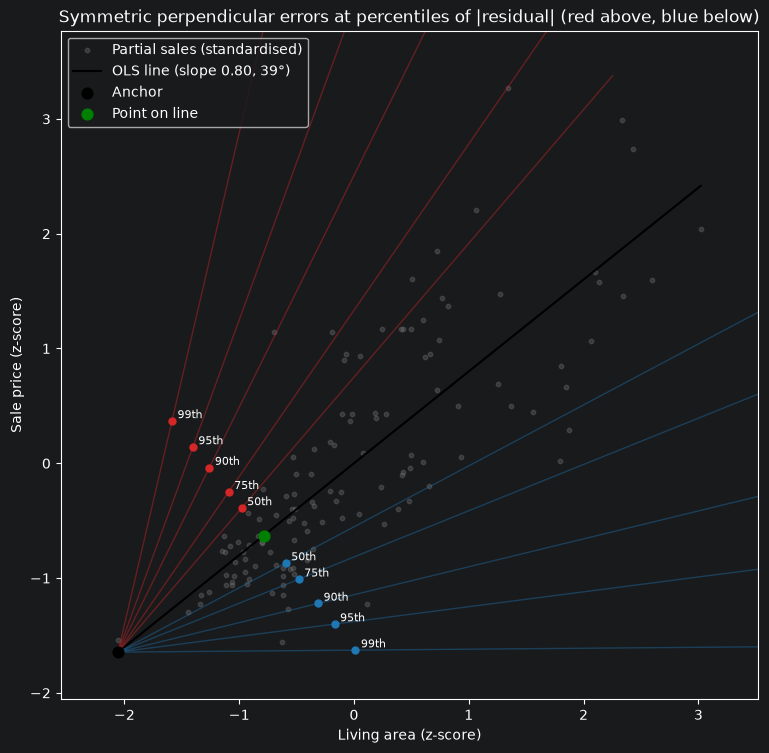

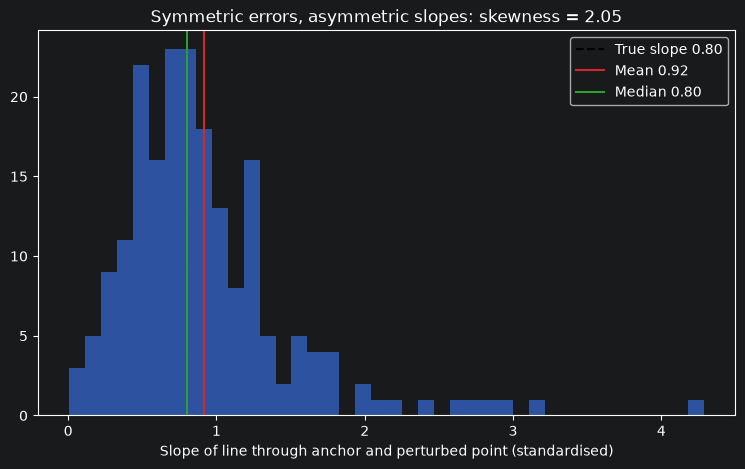

In [12]:
from scipy.stats import skew

# Line of best fit in standardised units (passes through the origin, since both variables are centred)
m = (zx @ zy) / (zx @ zx)
theta0 = np.degrees(np.arctan(m))

# Perpendicular residuals: vertical residual scaled onto the normal direction
d = (zy - m * zx) / np.sqrt(1 + m**2)

u = np.array([1, m]) / np.sqrt(1 + m**2)      # unit vector along the line
nvec = np.array([-m, 1]) / np.sqrt(1 + m**2)  # unit vector perpendicular to the line

frac = 0.25                                   # second point a quarter of the way along the data
P0 = np.array([zx.min(), m * zx.min()])       # anchor at the start of the line
L = frac * (zx.max() - zx.min()) * np.sqrt(1 + m**2)
P1 = P0 + L * u

# Perpendicular offsets at every percentile of |d|, in both directions
pcts = np.arange(1, 100)
mags = np.percentile(np.abs(d), pcts)
offsets = np.concatenate([-mags[::-1], mags])
Q = P1 + offsets[:, None] * nvec              # perturbed points, shape (198, 2)
slopes = (Q[:, 1] - P0[1]) / (Q[:, 0] - P0[0])

# Plot 1: geometry
major = [50, 75, 90, 95, 99]
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(zx, zy, s=10, alpha=0.3, color="grey", label="Partial sales (standardised)")
xs = np.linspace(zx.min(), zx.max(), 100)
ax.plot(xs, m * xs, color="black", linewidth=1.5, label=f"OLS line (slope {m:.2f}, {theta0:.0f}°)")
for p in major:
    mag = np.percentile(np.abs(d), p)
    for sign, colour in [(+1, "tab:red"), (-1, "tab:blue")]:
        q = P1 + sign * mag * nvec
        ax.plot([P0[0], q[0] + (q[0] - P0[0]) * 3], [P0[1], q[1] + (q[1] - P0[1]) * 3],
                color=colour, alpha=0.4, linewidth=1)
        ax.scatter(*q, color=colour, s=25, zorder=3)
        ax.annotate(f"{p}th", q, fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.scatter(*P0, color="black", s=60, zorder=4, label="Anchor")
ax.scatter(*P1, color="green", s=60, zorder=4, label="Point on line")
ax.set_aspect("equal")                        # essential: otherwise 'perpendicular' isn't visibly perpendicular
ax.set_xlim(zx.min() - 0.5, zx.max() + 0.5); ax.set_ylim(zy.min() - 0.5, zy.max() + 0.5)
ax.set_xlabel("Living area (z-score)"); ax.set_ylabel("Sale price (z-score)")
ax.set_title("Symmetric perpendicular errors at percentiles of |residual| (red above, blue below)")
ax.legend(loc="upper left"); plt.show()

# Plot 2: resulting slopes
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(slopes, bins=40, alpha=0.7)
ax.axvline(m, color="black", linestyle="--", label=f"True slope {m:.2f}")
ax.axvline(slopes.mean(), color="tab:red", label=f"Mean {slopes.mean():.2f}")
ax.axvline(np.median(slopes), color="tab:green", label=f"Median {np.median(slopes):.2f}")
ax.set_xlabel("Slope of line through anchor and perturbed point (standardised)")
ax.set_title(f"Symmetric errors, asymmetric slopes: skewness = {skew(slopes):.2f}")
ax.legend(); plt.show()

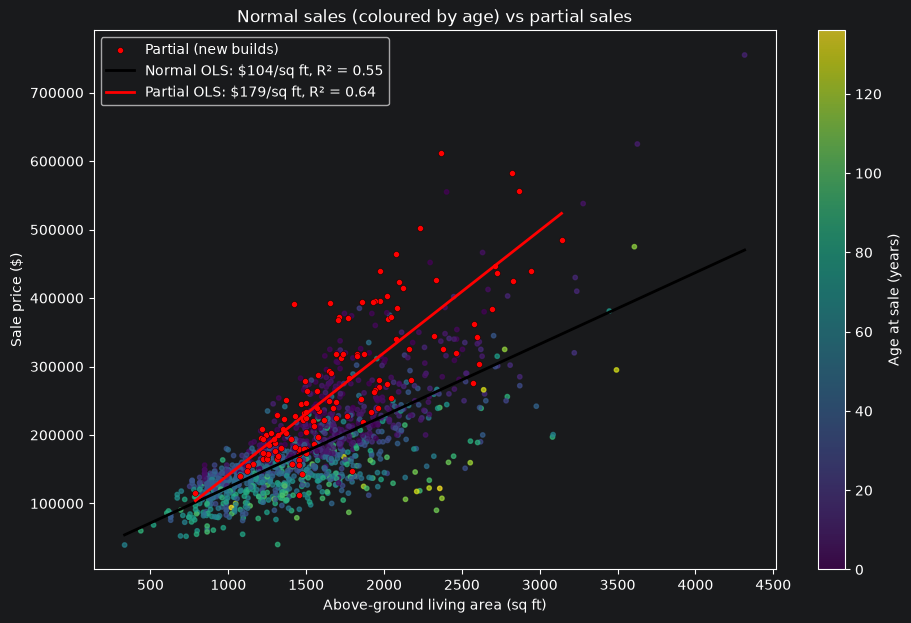

In [13]:
normal = train[train["SaleCondition"] == "Normal"].copy()
normal["Age"] = normal["YrSold"] - normal["YearBuilt"]

fig, ax = plt.subplots(figsize=(11, 7))

# Normal sales, coloured by age
sc = ax.scatter(normal["GrLivArea"], normal["SalePrice"], c=normal["Age"],
                cmap="viridis", s=10, alpha=0.7)
fig.colorbar(sc, ax=ax, label="Age at sale (years)")

# Partial sales, one colour
ax.scatter(partial["GrLivArea"], partial["SalePrice"], color="red", s=18,
           edgecolor="black", linewidth=0.3, label="Partial (new builds)")

# Separate OLS line for each group
for g, name, colour in [(normal, "Normal", "black"), (partial, "Partial", "red")]:
    x = g["GrLivArea"].values.astype(float)
    y = g["SalePrice"].values.astype(float)
    fit = sm.OLS(y, sm.add_constant(x)).fit()
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, fit.params[0] + fit.params[1] * xs, color=colour, linewidth=2,
            label=f"{name} OLS: ${fit.params[1]:,.0f}/sq ft, R² = {fit.rsquared:.2f}")

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Normal sales (coloured by age) vs partial sales")
ax.legend(loc="upper left")
plt.show()

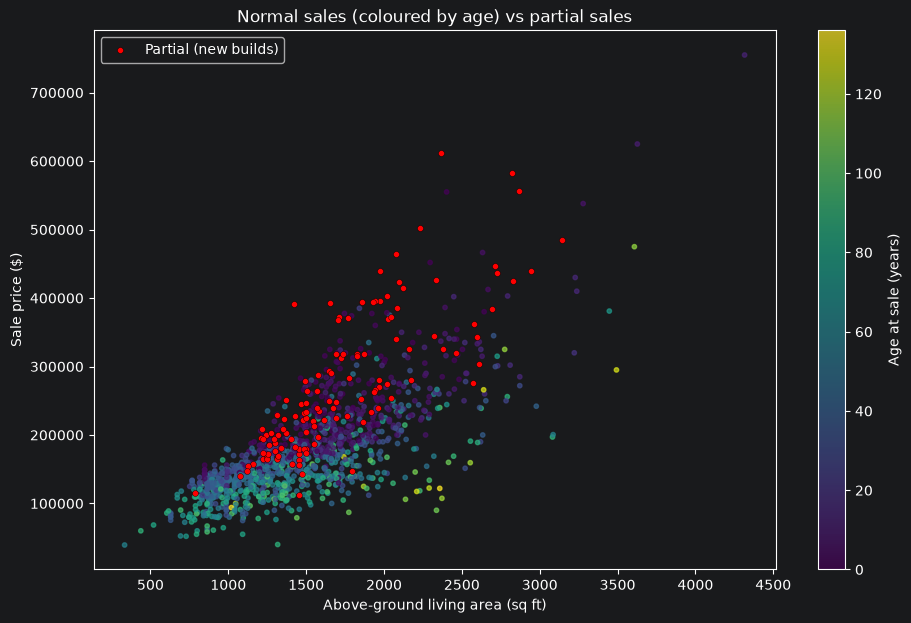

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")

# Normal sales, with age at sale
normal = train[train["SaleCondition"] == "Normal"].copy()
normal["Age"] = normal["YrSold"] - normal["YearBuilt"]

# Partial sales, with the two anomalous houses removed
partial = train[train["SaleCondition"] == "Partial"]
anomalous = (partial["GrLivArea"] > 4000) & (partial["SalePrice"] < 300_000)
partial = partial[~anomalous]

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(normal["GrLivArea"], normal["SalePrice"], c=normal["Age"],
                cmap="viridis", s=10, alpha=0.7)
fig.colorbar(sc, ax=ax, label="Age at sale (years)")
ax.scatter(partial["GrLivArea"], partial["SalePrice"], color="red", s=18,
           edgecolor="black", linewidth=0.3, label="Partial (new builds)")

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Normal sales (coloured by age) vs partial sales")
ax.legend(loc="upper left")
plt.show()

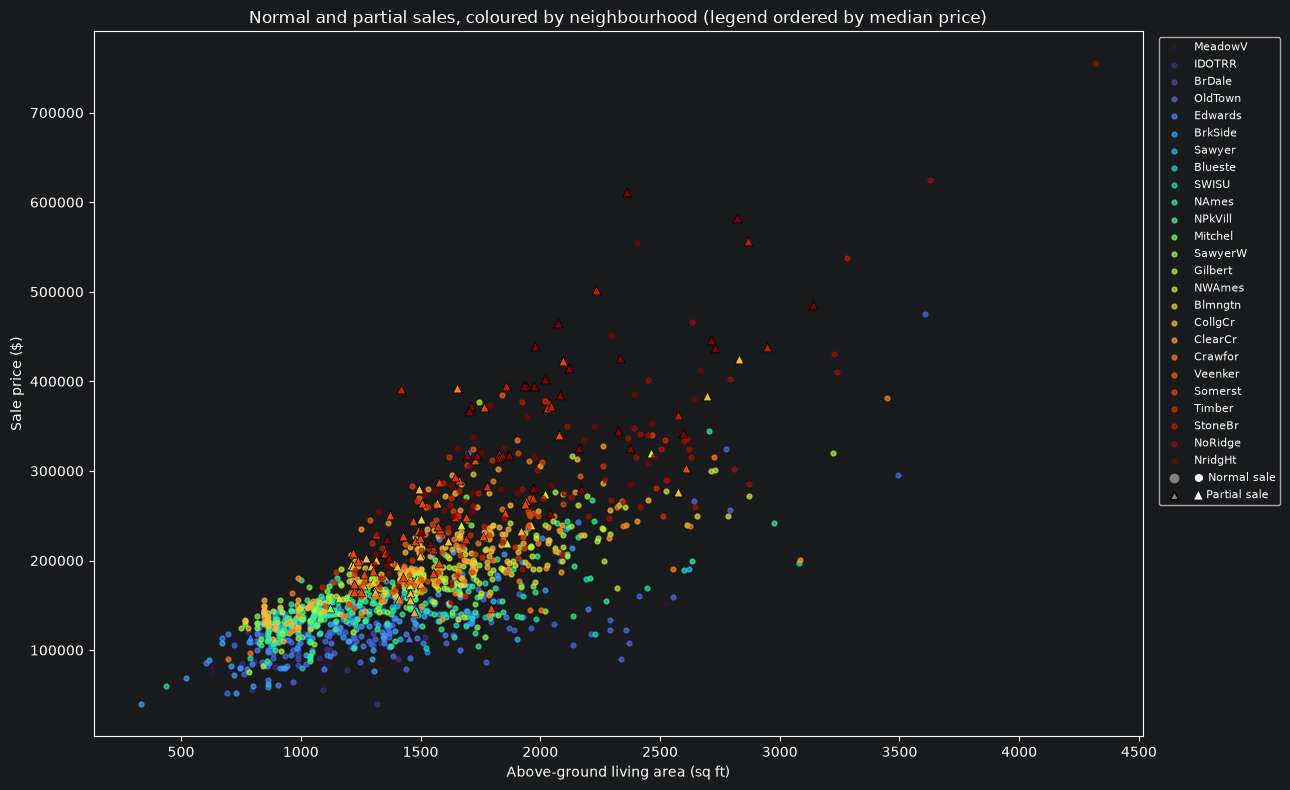

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")

normal = train[train["SaleCondition"] == "Normal"]
partial = train[train["SaleCondition"] == "Partial"]
anomalous = (partial["GrLivArea"] > 4000) & (partial["SalePrice"] < 300_000)
partial = partial[~anomalous]

# One distinct colour per neighbourhood, ordered by median price so similar colours ≈ similar prices
order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index
colours = plt.cm.turbo(np.linspace(0, 1, len(order)))
colour_of = dict(zip(order, colours))

fig, ax = plt.subplots(figsize=(13, 8))
for nbhd in order:
    n = normal[normal["Neighborhood"] == nbhd]
    p = partial[partial["Neighborhood"] == nbhd]
    ax.scatter(n["GrLivArea"], n["SalePrice"], color=colour_of[nbhd], s=12, alpha=0.7, label=nbhd)
    ax.scatter(p["GrLivArea"], p["SalePrice"], color=colour_of[nbhd], s=40, marker="^",
               edgecolor="black", linewidth=0.5)

ax.scatter([], [], color="grey", marker="o", label="● Normal sale")
ax.scatter([], [], color="grey", marker="^", edgecolor="black", label="▲ Partial sale")

ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.set_title("Normal and partial sales, coloured by neighbourhood (legend ordered by median price)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, ncol=1)
plt.tight_layout(); plt.show()

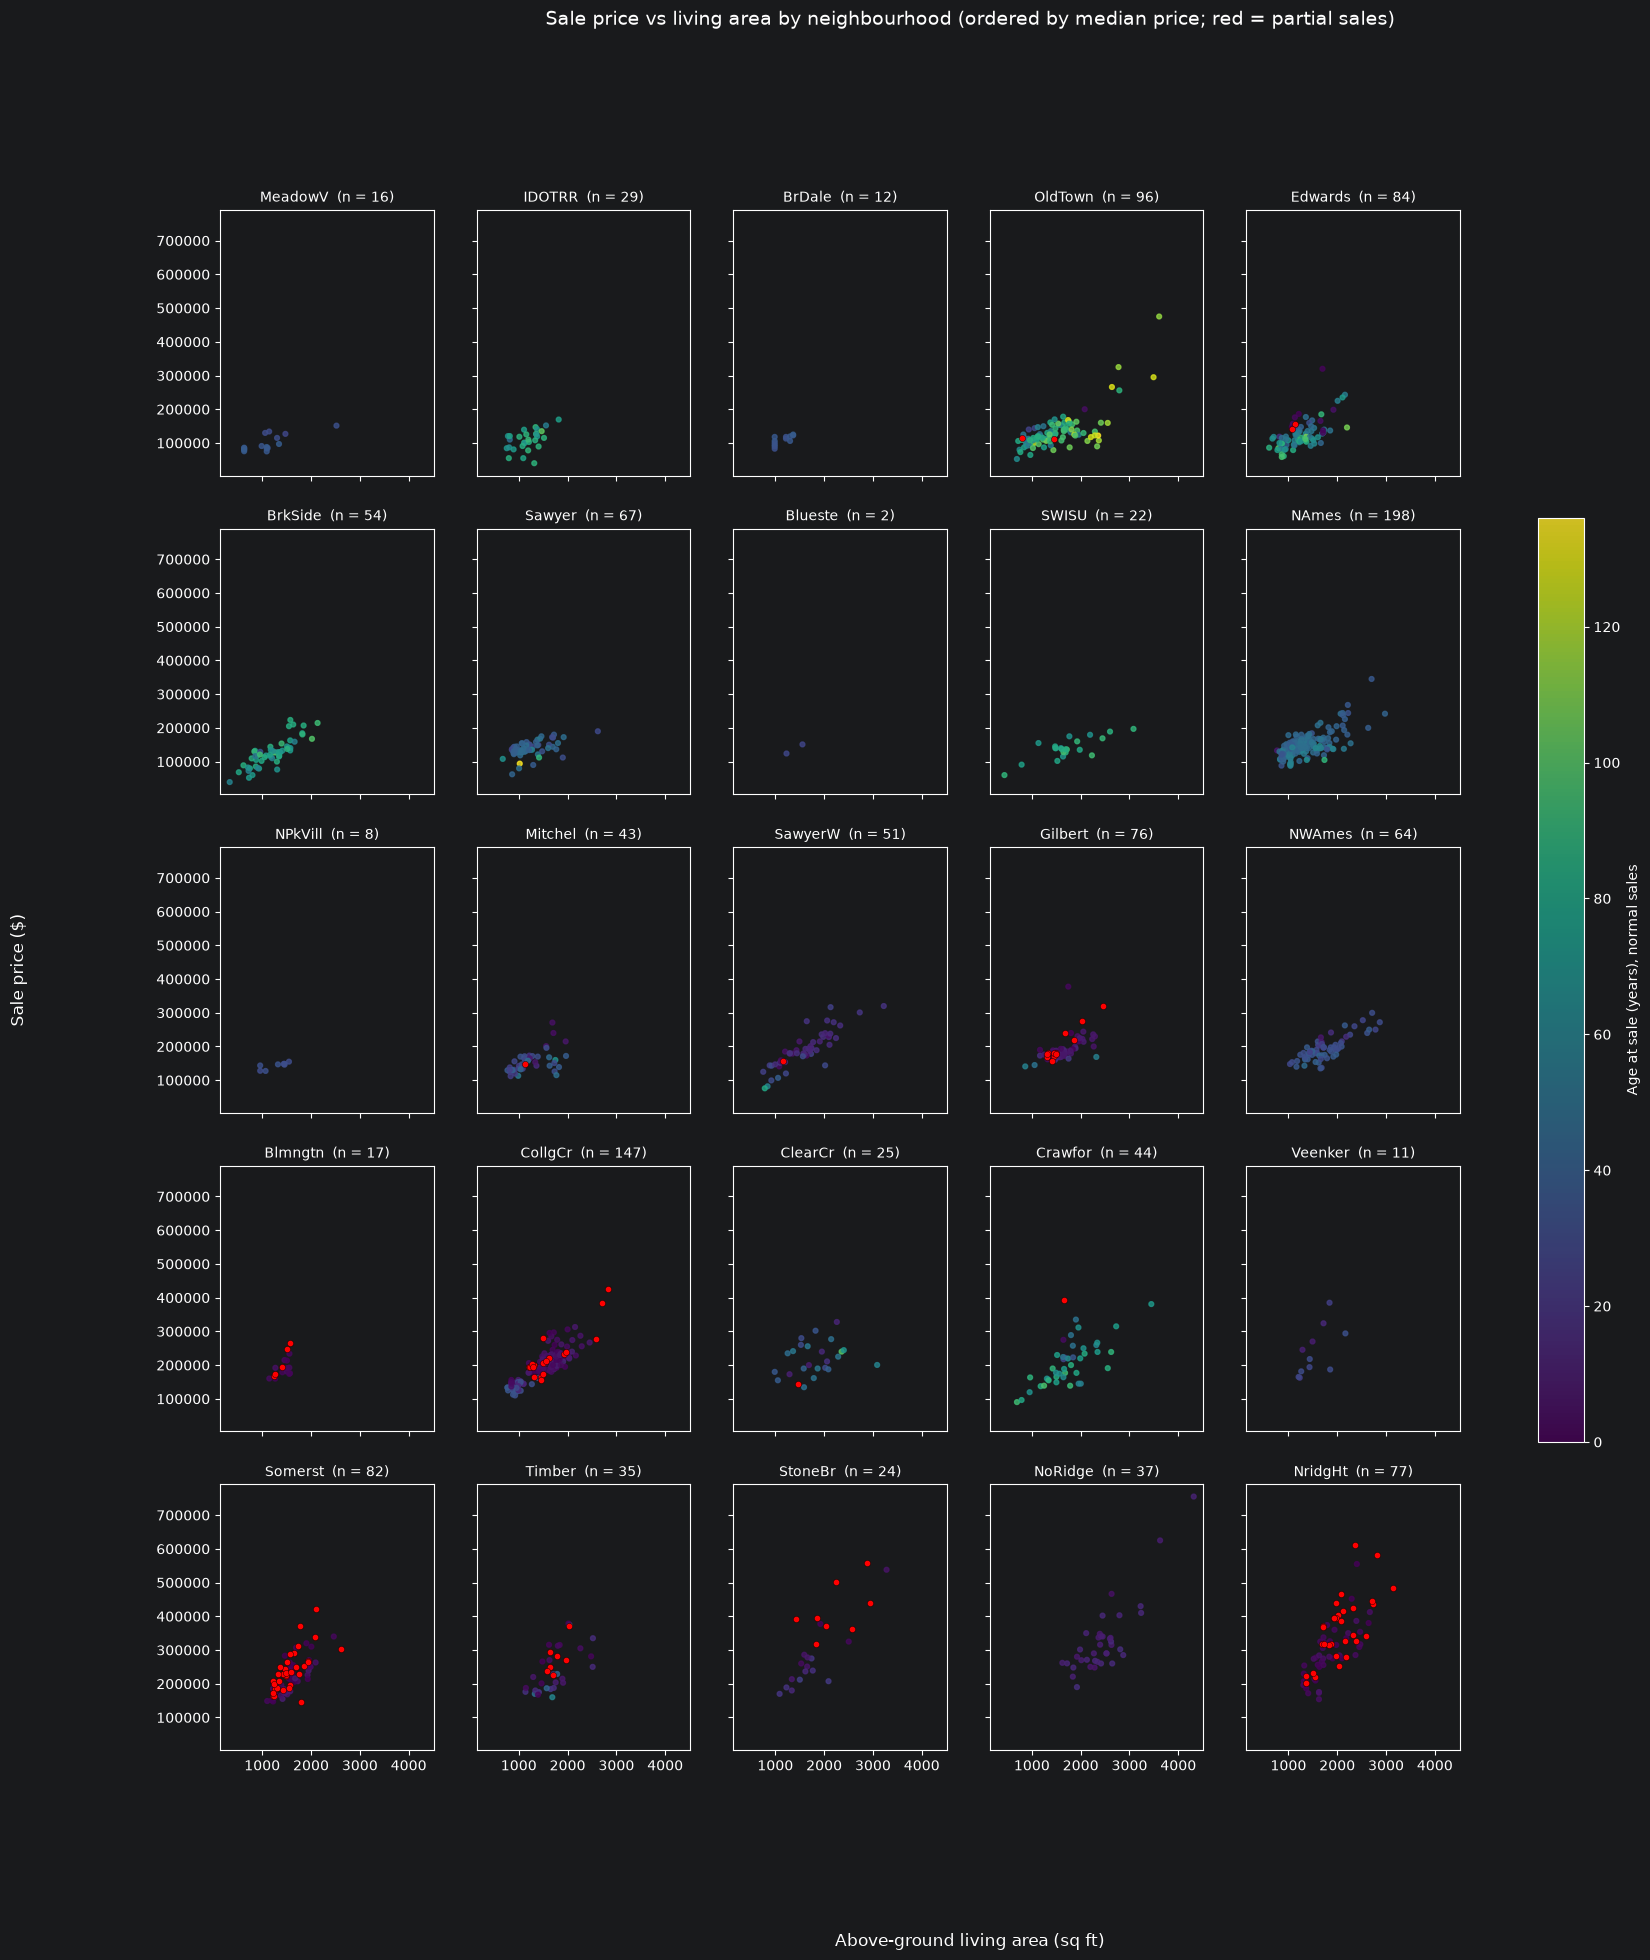

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")

normal = train[train["SaleCondition"] == "Normal"].copy()
normal["Age"] = normal["YrSold"] - normal["YearBuilt"]
partial = train[train["SaleCondition"] == "Partial"]
anomalous = (partial["GrLivArea"] > 4000) & (partial["SalePrice"] < 300_000)
partial = partial[~anomalous]

order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index
age_min, age_max = normal["Age"].min(), normal["Age"].max()   # one colour scale for all panels

ncols = 5
nrows = int(np.ceil(len(order) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 4 * nrows), sharex=True, sharey=True)

for ax, nbhd in zip(axes.flat, order):
    n = normal[normal["Neighborhood"] == nbhd]
    p = partial[partial["Neighborhood"] == nbhd]
    sc = ax.scatter(n["GrLivArea"], n["SalePrice"], c=n["Age"], cmap="viridis",
                    vmin=age_min, vmax=age_max, s=12, alpha=0.8)
    ax.scatter(p["GrLivArea"], p["SalePrice"], color="red", s=20,
               edgecolor="black", linewidth=0.3)
    ax.set_title(f"{nbhd}  (n = {len(n) + len(p)})", fontsize=10)

for ax in axes.flat[len(order):]:      # hide unused panels
    ax.axis("off")

fig.colorbar(sc, ax=axes, label="Age at sale (years), normal sales", shrink=0.6)
fig.supxlabel("Above-ground living area (sq ft)")
fig.supylabel("Sale price ($)")
fig.suptitle("Sale price vs living area by neighbourhood (ordered by median price; red = partial sales)",
             fontsize=14)
plt.show()

Houses alone in their neighbourhood (no other houses to take a median of): 0
Variance explained: [0.63 0.27 0.1 ]
                   PC1    PC2
NbhdMedianPrice -0.661  0.102
Age              0.587 -0.547
GrLivArea       -0.467 -0.831


/var/folders/x6/5x_xkwxd38n7sffvtqgf2p_r0000gn/T/ipykernel_68802/2137287360.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(); ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)


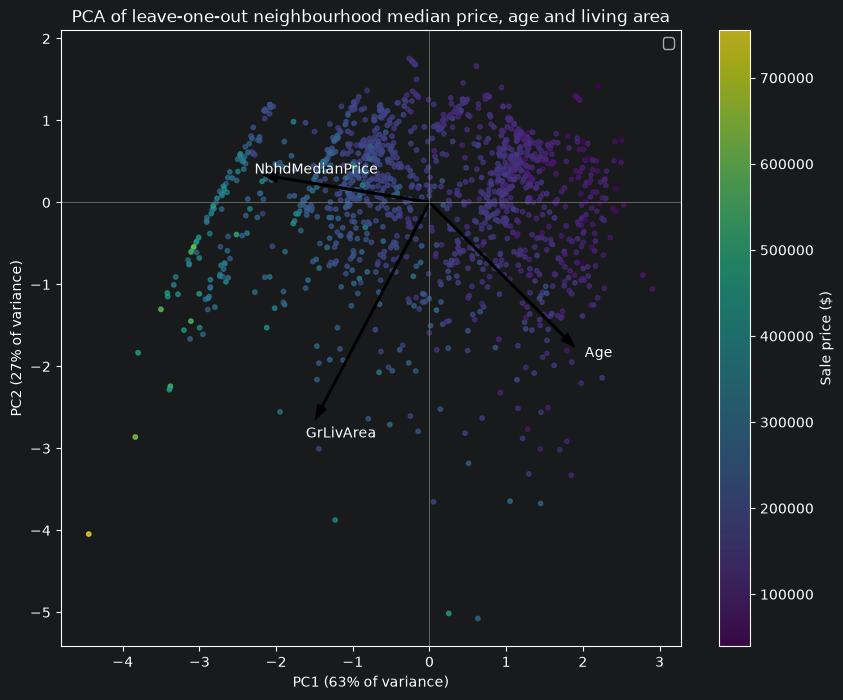

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv("../data/train.csv")
df = train[train["SaleCondition"].isin(["Normal", "Partial"])].copy()
anomalous = (df["SaleCondition"] == "Partial") & (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300_000)
df = df[~anomalous]

# Leave-one-out neighbourhood median: each house gets the median of the OTHER houses in its neighbourhood
def loo_median(prices):
    v = prices.values
    out = [np.median(np.delete(v, i)) if len(v) > 1 else np.nan for i in range(len(v))]
    return pd.Series(out, index=prices.index)

df["NbhdMedianPrice"] = df.groupby("Neighborhood")["SalePrice"].transform(loo_median)
n_missing = df["NbhdMedianPrice"].isna().sum()
print(f"Houses alone in their neighbourhood (no other houses to take a median of): {n_missing}")
df = df.dropna(subset=["NbhdMedianPrice"])

df["Age"] = df["YrSold"] - df["YearBuilt"]
features = ["NbhdMedianPrice", "Age", "GrLivArea"]
X = df[features].values.astype(float)

# 1. Standardise
Z = (X - X.mean(axis=0)) / X.std(axis=0)

# 2. PCA via SVD
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
explained = S**2 / np.sum(S**2)
scores = Z @ Vt[:2].T

print("Variance explained:", np.round(explained, 3))
print(pd.DataFrame(Vt[:2].T, index=features, columns=["PC1", "PC2"]).round(3))

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(scores[:, 0], scores[:, 1], c=df["SalePrice"], cmap="viridis", s=10, alpha=0.7)
fig.colorbar(sc, label="Sale price ($)")

arrow_scale = 3
for i, f in enumerate(features):
    ax.arrow(0, 0, Vt[0, i] * arrow_scale, Vt[1, i] * arrow_scale,
             color="black", width=0.02, head_width=0.12)
    ax.text(Vt[0, i] * arrow_scale * 1.15, Vt[1, i] * arrow_scale * 1.15, f, fontsize=10)

ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variance)")
ax.set_title("PCA of leave-one-out neighbourhood median price, age and living area")
ax.legend(); ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
plt.show()

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.754
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     2020.
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:57:29   Log-Likelihood:                -15843.
No. Observations:                1321   AIC:                         3.169e+04
Df Residuals:                    1318   BIC:                         3.171e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.844e+05   1077.503    171.131      0.0

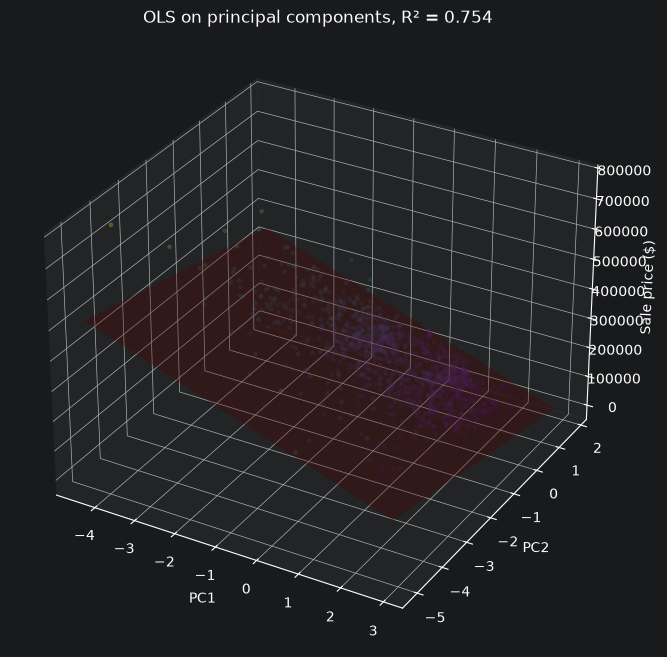

In [19]:
import statsmodels.api as sm

y = df["SalePrice"].values.astype(float)

# OLS on the two principal components
pcr = sm.OLS(y, sm.add_constant(scores)).fit()
print(pcr.summary(xname=["const", "PC1", "PC2"]))

# For comparison: OLS on all three original (standardised) features
full = sm.OLS(y, sm.add_constant(Z)).fit()
print(f"\nR² using PC1 + PC2:          {pcr.rsquared:.3f}")
print(f"R² using all 3 features:     {full.rsquared:.3f}")

# Plot: data and fitted plane in PC space
b0, b1, b2 = pcr.params
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(scores[:, 0], scores[:, 1], y, c=y, cmap="viridis", s=6, alpha=0.5)
g1, g2 = np.meshgrid(np.linspace(scores[:, 0].min(), scores[:, 0].max(), 30),
                     np.linspace(scores[:, 1].min(), scores[:, 1].max(), 30))
ax.plot_surface(g1, g2, b0 + b1 * g1 + b2 * g2, color="red", alpha=0.3)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("Sale price ($)")
ax.set_title(f"OLS on principal components, R² = {pcr.rsquared:.3f}")
plt.show()

Residual skewness = 1.43 (normal: 0), kurtosis = 9.58 (normal: 3)
Skew-t parameters: a = 1.81, b = 1.85 (a > b means right skew), loc = -160, scale = 26,359


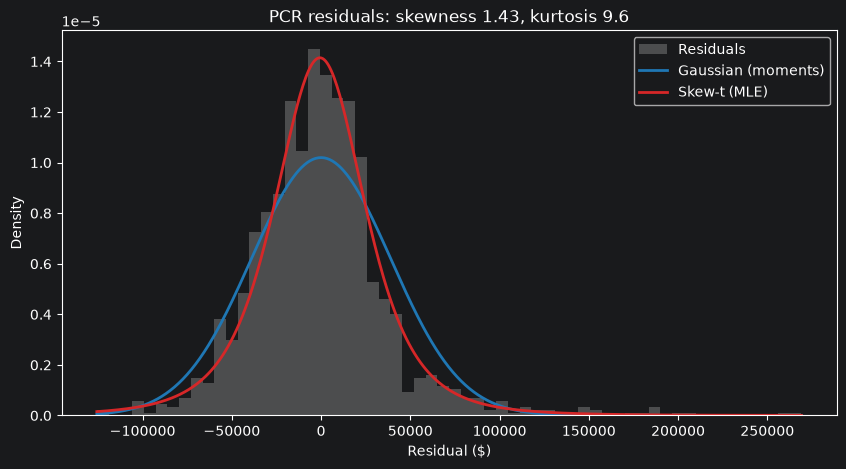

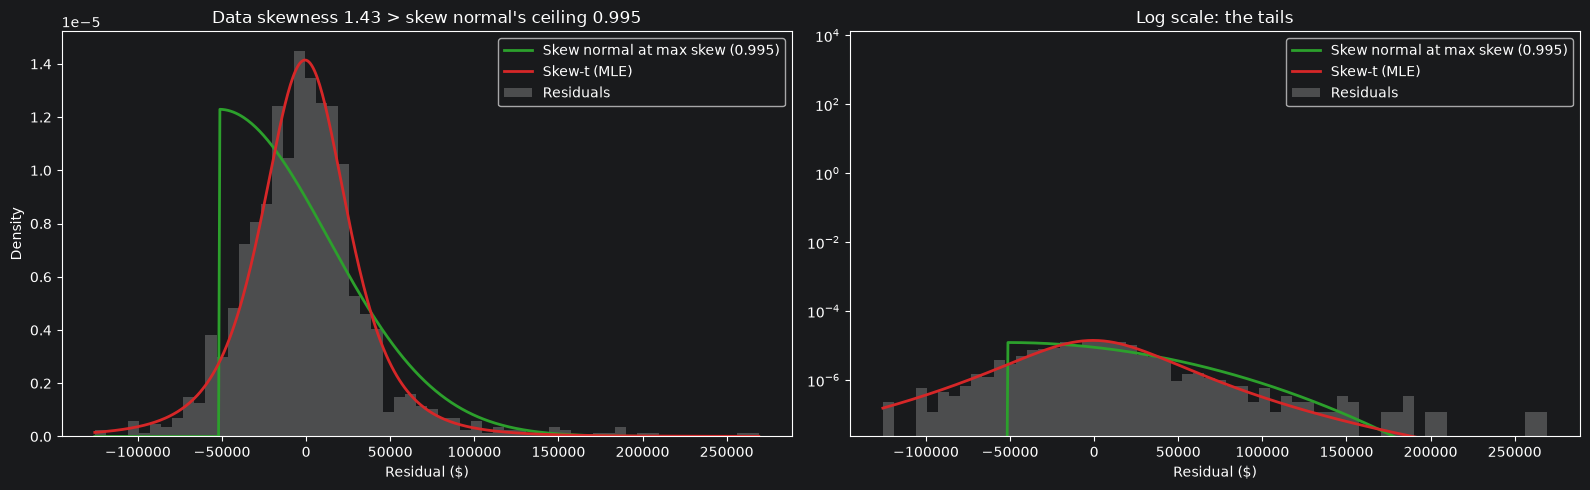

In [20]:
from scipy import stats

resid = pcr.resid
xs = np.linspace(resid.min(), resid.max(), 500)
s_skew, s_kurt = stats.skew(resid), stats.kurtosis(resid, fisher=False)
print(f"Residual skewness = {s_skew:.2f} (normal: 0), kurtosis = {s_kurt:.2f} (normal: 3)")

# Gaussian: method of moments
mu, sd = resid.mean(), resid.std()

# Skew Student-t (Jones–Faddy): maximum likelihood, since its moment equations are messy
a, b, loc_t, scale_t = stats.jf_skew_t.fit(resid)
print(f"Skew-t parameters: a = {a:.2f}, b = {b:.2f} (a > b means right skew), loc = {loc_t:,.0f}, scale = {scale_t:,.0f}")

# ---- Figure 1: residuals with Gaussian and skew-t ----
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(resid, bins=60, density=True, alpha=0.5, color="grey", label="Residuals")
ax.plot(xs, stats.norm.pdf(xs, mu, sd), color="tab:blue", lw=2, label="Gaussian (moments)")
ax.plot(xs, stats.jf_skew_t.pdf(xs, a, b, loc_t, scale_t), color="tab:red", lw=2, label="Skew-t (MLE)")
ax.set_xlabel("Residual ($)"); ax.set_ylabel("Density")
ax.set_title(f"PCR residuals: skewness {s_skew:.2f}, kurtosis {s_kurt:.1f}")
ax.legend(); plt.show()

# ---- Figure 2: the skew normal at its maximum skewness ----
alpha = 1000                                     # effectively infinite shape → maximum skew
delta = alpha / np.sqrt(1 + alpha**2)
max_skew = stats.skewnorm.stats(alpha, moments="s")
omega = sd / np.sqrt(1 - 2 * delta**2 / np.pi)   # match the variance
xi = mu - omega * delta * np.sqrt(2 / np.pi)     # match the mean
sn_pdf = stats.skewnorm.pdf(xs, alpha, xi, omega)

counts, edges = np.histogram(resid, bins=60, density=True)
centres = (edges[:-1] + edges[1:]) / 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, log in zip(axes, [False, True]):
    ax.bar(centres, counts, width=edges[1] - edges[0], alpha=0.5, color="grey", label="Residuals")
    ax.plot(xs, sn_pdf, color="tab:green", lw=2,
            label=f"Skew normal at max skew ({float(max_skew):.3f})")
    ax.plot(xs, stats.jf_skew_t.pdf(xs, a, b, loc_t, scale_t), color="tab:red", lw=2, label="Skew-t (MLE)")
    ax.set_xlabel("Residual ($)")
    if log:
        ax.set_yscale("log"); ax.set_ylim(counts[counts > 0].min() / 5, None)
        ax.set_title("Log scale: the tails")
    else:
        ax.set_title(f"Data skewness {s_skew:.2f} > skew normal's ceiling {float(max_skew):.3f}")
    ax.legend()
axes[0].set_ylabel("Density")
plt.tight_layout(); plt.show()

In [21]:
pd.set_option("display.max_columns", 30)

out = df.copy()
out["Predicted"] = pcr.fittedvalues
out["Residual"] = pcr.resid
out["Resid_σ"] = out["Residual"] / np.sqrt(pcr.scale)   # residual in standard deviations

important = ["SalePrice", "Predicted", "Residual", "Resid_σ",
             "Neighborhood", "NbhdMedianPrice", "GrLivArea", "Age", "YearRemodAdd",
             "OverallQual", "OverallCond", "TotalBsmtSF", "GarageCars", "LotArea",
             "HouseStyle", "BldgType", "MSZoning", "SaleType", "SaleCondition"]

N = 15
largest = out.loc[out["Residual"].abs().nlargest(N).index, important].sort_values("Residual")
display(largest.style.format({"SalePrice": "{:,.0f}", "Predicted": "{:,.0f}", "Residual": "{:+,.0f}",
                              "Resid_σ": "{:+.1f}", "NbhdMedianPrice": "{:,.0f}", "LotArea": "{:,.0f}"})
                     .background_gradient(subset=["Resid_σ"], cmap="coolwarm"))

,SalePrice,Predicted,Residual,Resid_σ,Neighborhood,NbhdMedianPrice,GrLivArea,Age,YearRemodAdd,OverallQual,OverallCond,TotalBsmtSF,GarageCars,LotArea,HouseStyle,BldgType,MSZoning,SaleType,SaleCondition
769,"538,000","398,684","+139,316",+3.6,StoneBr,"278,000",3279,7,2003,8,5,1650,3,"53,504",2Story,1Fam,RL,WD,Normal
1243,"465,000","318,553","+146,447",+3.7,NridgHt,"314,906",2076,0,2006,10,5,2076,3,"13,891",1Story,1Fam,RL,New,Partial
688,"392,000","243,864","+148,136",+3.8,StoneBr,"278,000",1419,0,2007,8,6,1419,2,"8,089",1Story,1Fam,RL,New,Partial
664,"423,000","274,497","+148,503",+3.8,Somerst,"226,000",2097,1,2006,8,5,2077,3,"20,896",1Story,1Fam,RL,New,Partial
53,"385,000","231,257","+153,743",+3.9,Veenker,"206,000",1842,25,1987,9,5,1842,3,"50,271",1Story,1Fam,RL,WD,Normal
1388,"377,500","220,492","+157,008",+4.0,Gilbert,"180,500",1746,3,2007,9,5,1746,3,"14,892",1Story,1Fam,RL,WD,Normal
1181,"392,500","219,277","+173,223",+4.4,Crawfor,"191,000",1652,0,2008,8,5,1600,2,"5,587",1Story,TwnhsE,RM,New,Partial
185,"475,000","295,407","+179,593",+4.6,OldTown,"120,000",3608,114,1993,10,9,1107,3,"22,950",2.5Fin,1Fam,RM,WD,Normal
178,"501,837","312,680","+189,157",+4.8,StoneBr,"278,000",2234,1,2009,9,5,2216,3,"17,423",1Story,1Fam,RL,New,Partial
1169,"625,000","435,435","+189,565",+4.8,NoRidge,"295,750",3627,11,1996,10,5,1930,3,"35,760",2Story,1Fam,RL,WD,Normal


In [22]:
pd.set_option("display.max_rows", 200)
display(out.loc[largest.index].T)

,769,1243,688,664,53,1388,1181,185,178,1169,1046,803,440,691,898
Id,770,1244,689,665,54,1389,1182,186,179,1170,1047,804,441,692,899
MSSubClass,60,20,20,20,20,20,120,75,20,60,60,60,20,60,20
MSZoning,RL,RL,RL,RL,RL,RL,RM,RM,RL,RL,RL,RL,RL,RL,RL
LotFrontage,47.0,107.0,60.0,49.0,68.0,42.0,64.0,90.0,63.0,118.0,85.0,107.0,105.0,104.0,100.0
LotArea,53504,13891,8089,20896,50271,14892,5587,22950,17423,35760,16056,13891,15431,21535,12919
Street,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave,Pave
Alley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,IR2,Reg,Reg,IR2,IR1,IR1,IR1,IR2,IR1,IR1,IR1,Reg,Reg,IR1,IR1
LandContour,HLS,Lvl,HLS,Lvl,Low,HLS,HLS,Lvl,Lvl,Lvl,Lvl,Lvl,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub,AllPub


Top 10 correlations with the residual:
BsmtFinSF1      0.390
TotalBsmtSF     0.370
1stFlrSF        0.307
BsmtFullBath    0.277
OverallQual     0.258
2ndFlrSF       -0.254
OverallCond     0.228
BedroomAbvGr   -0.224
KitchenAbvGr   -0.215
GarageArea      0.212
dtype: float64

44 qualitative columns


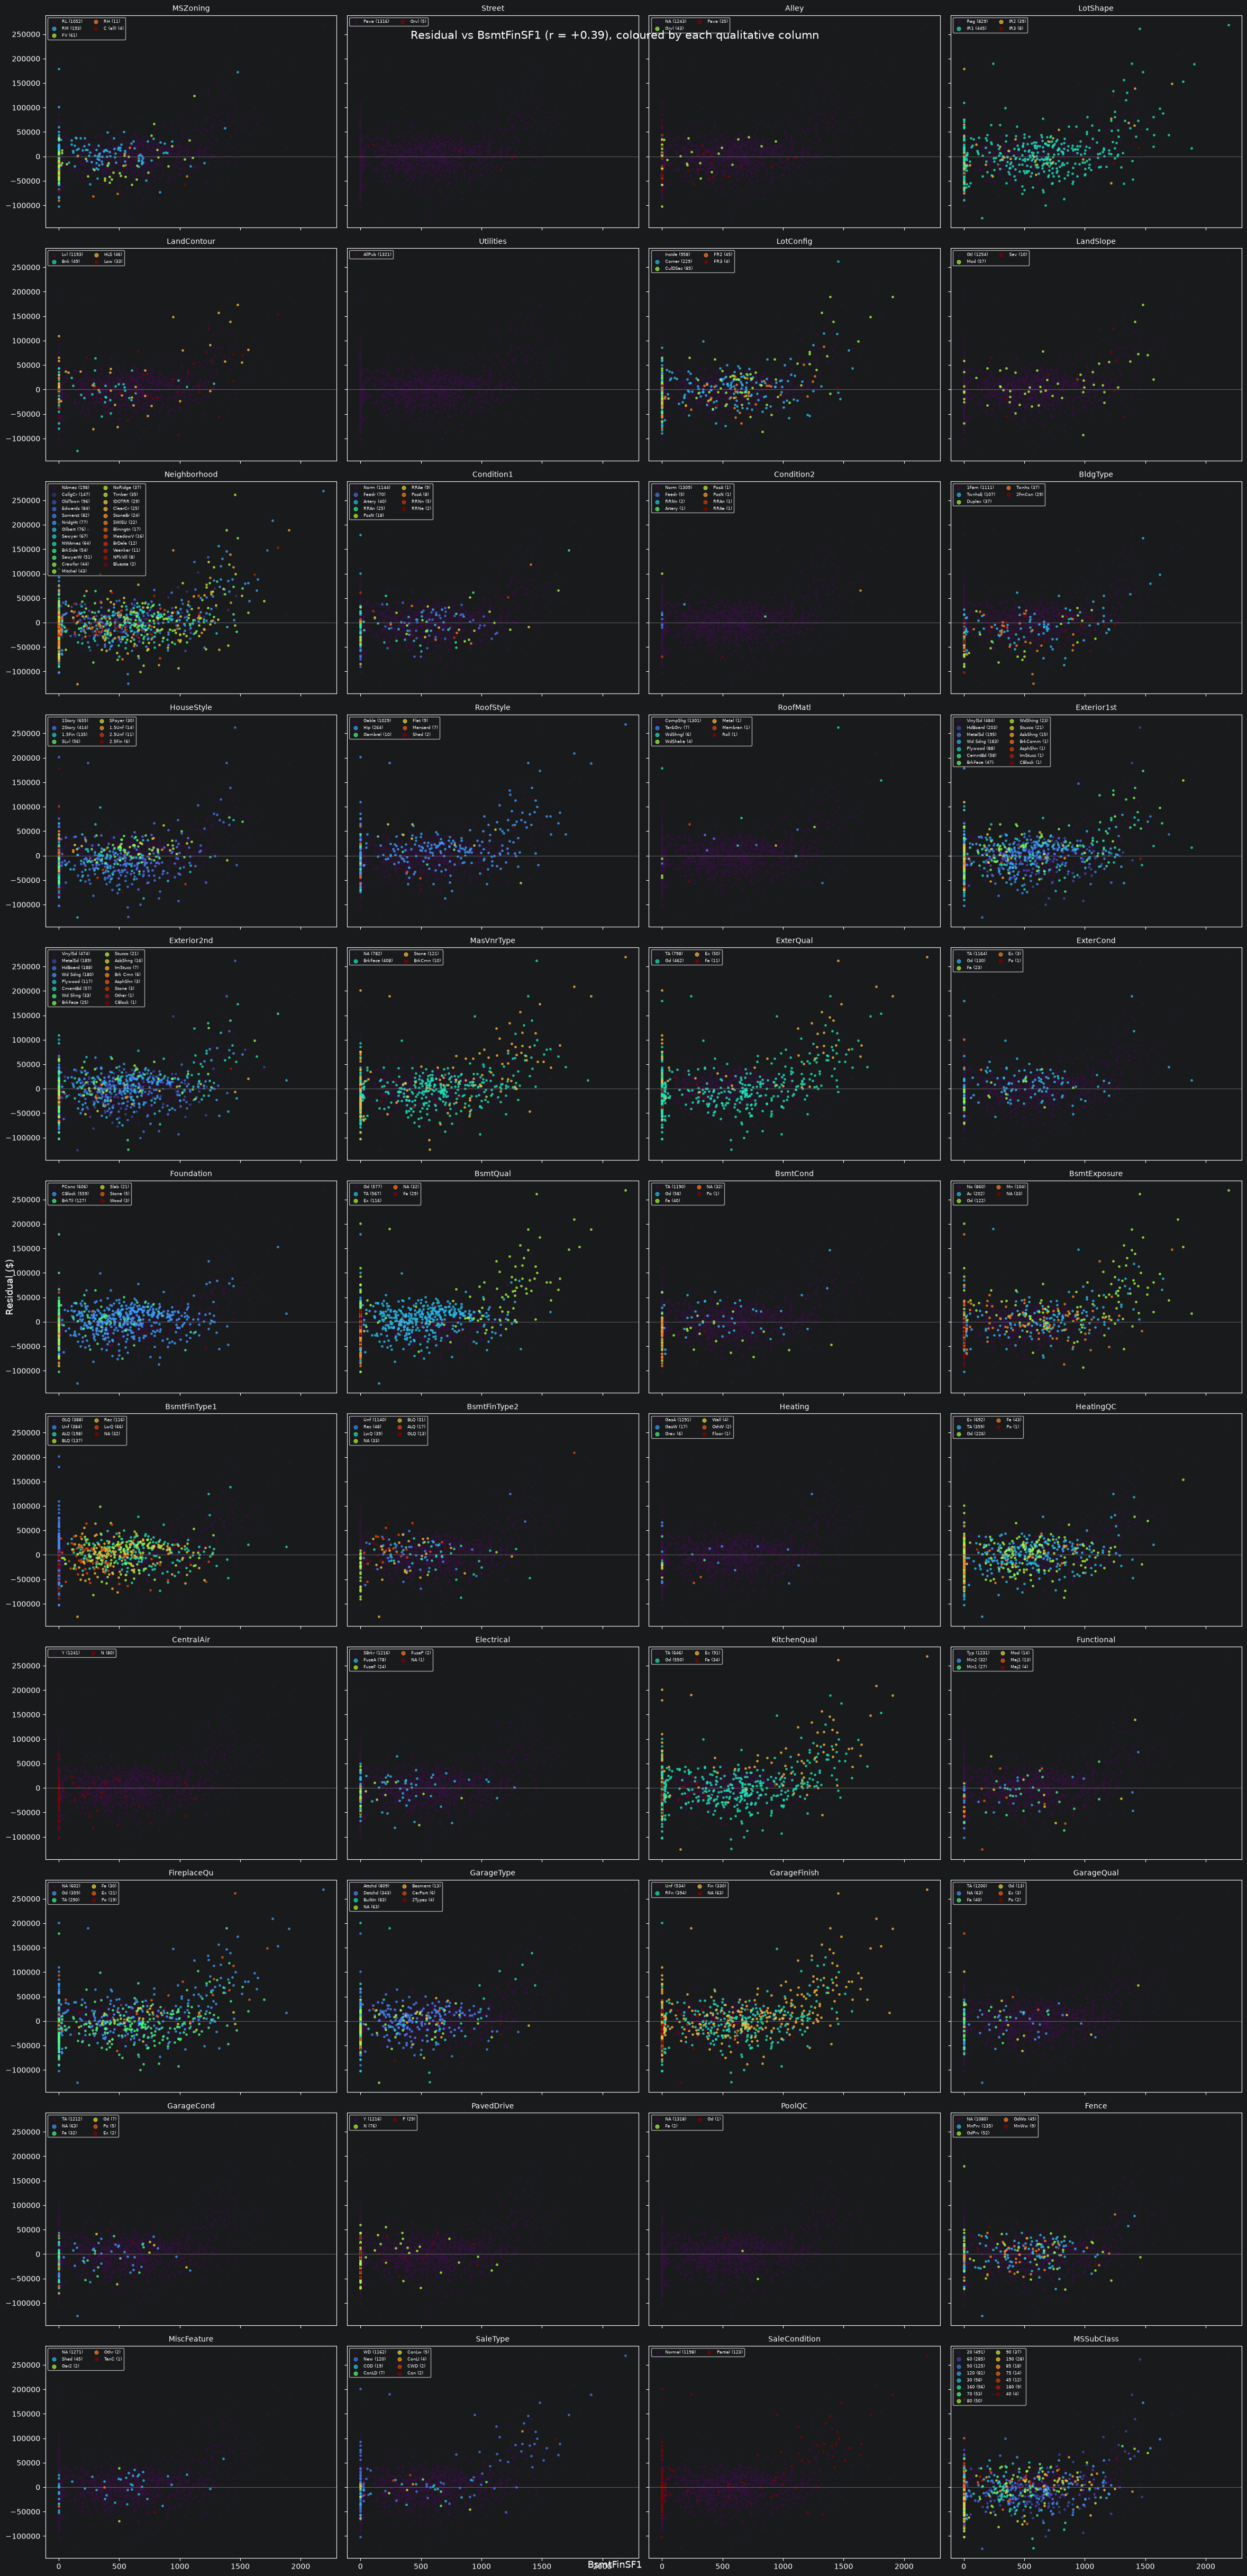

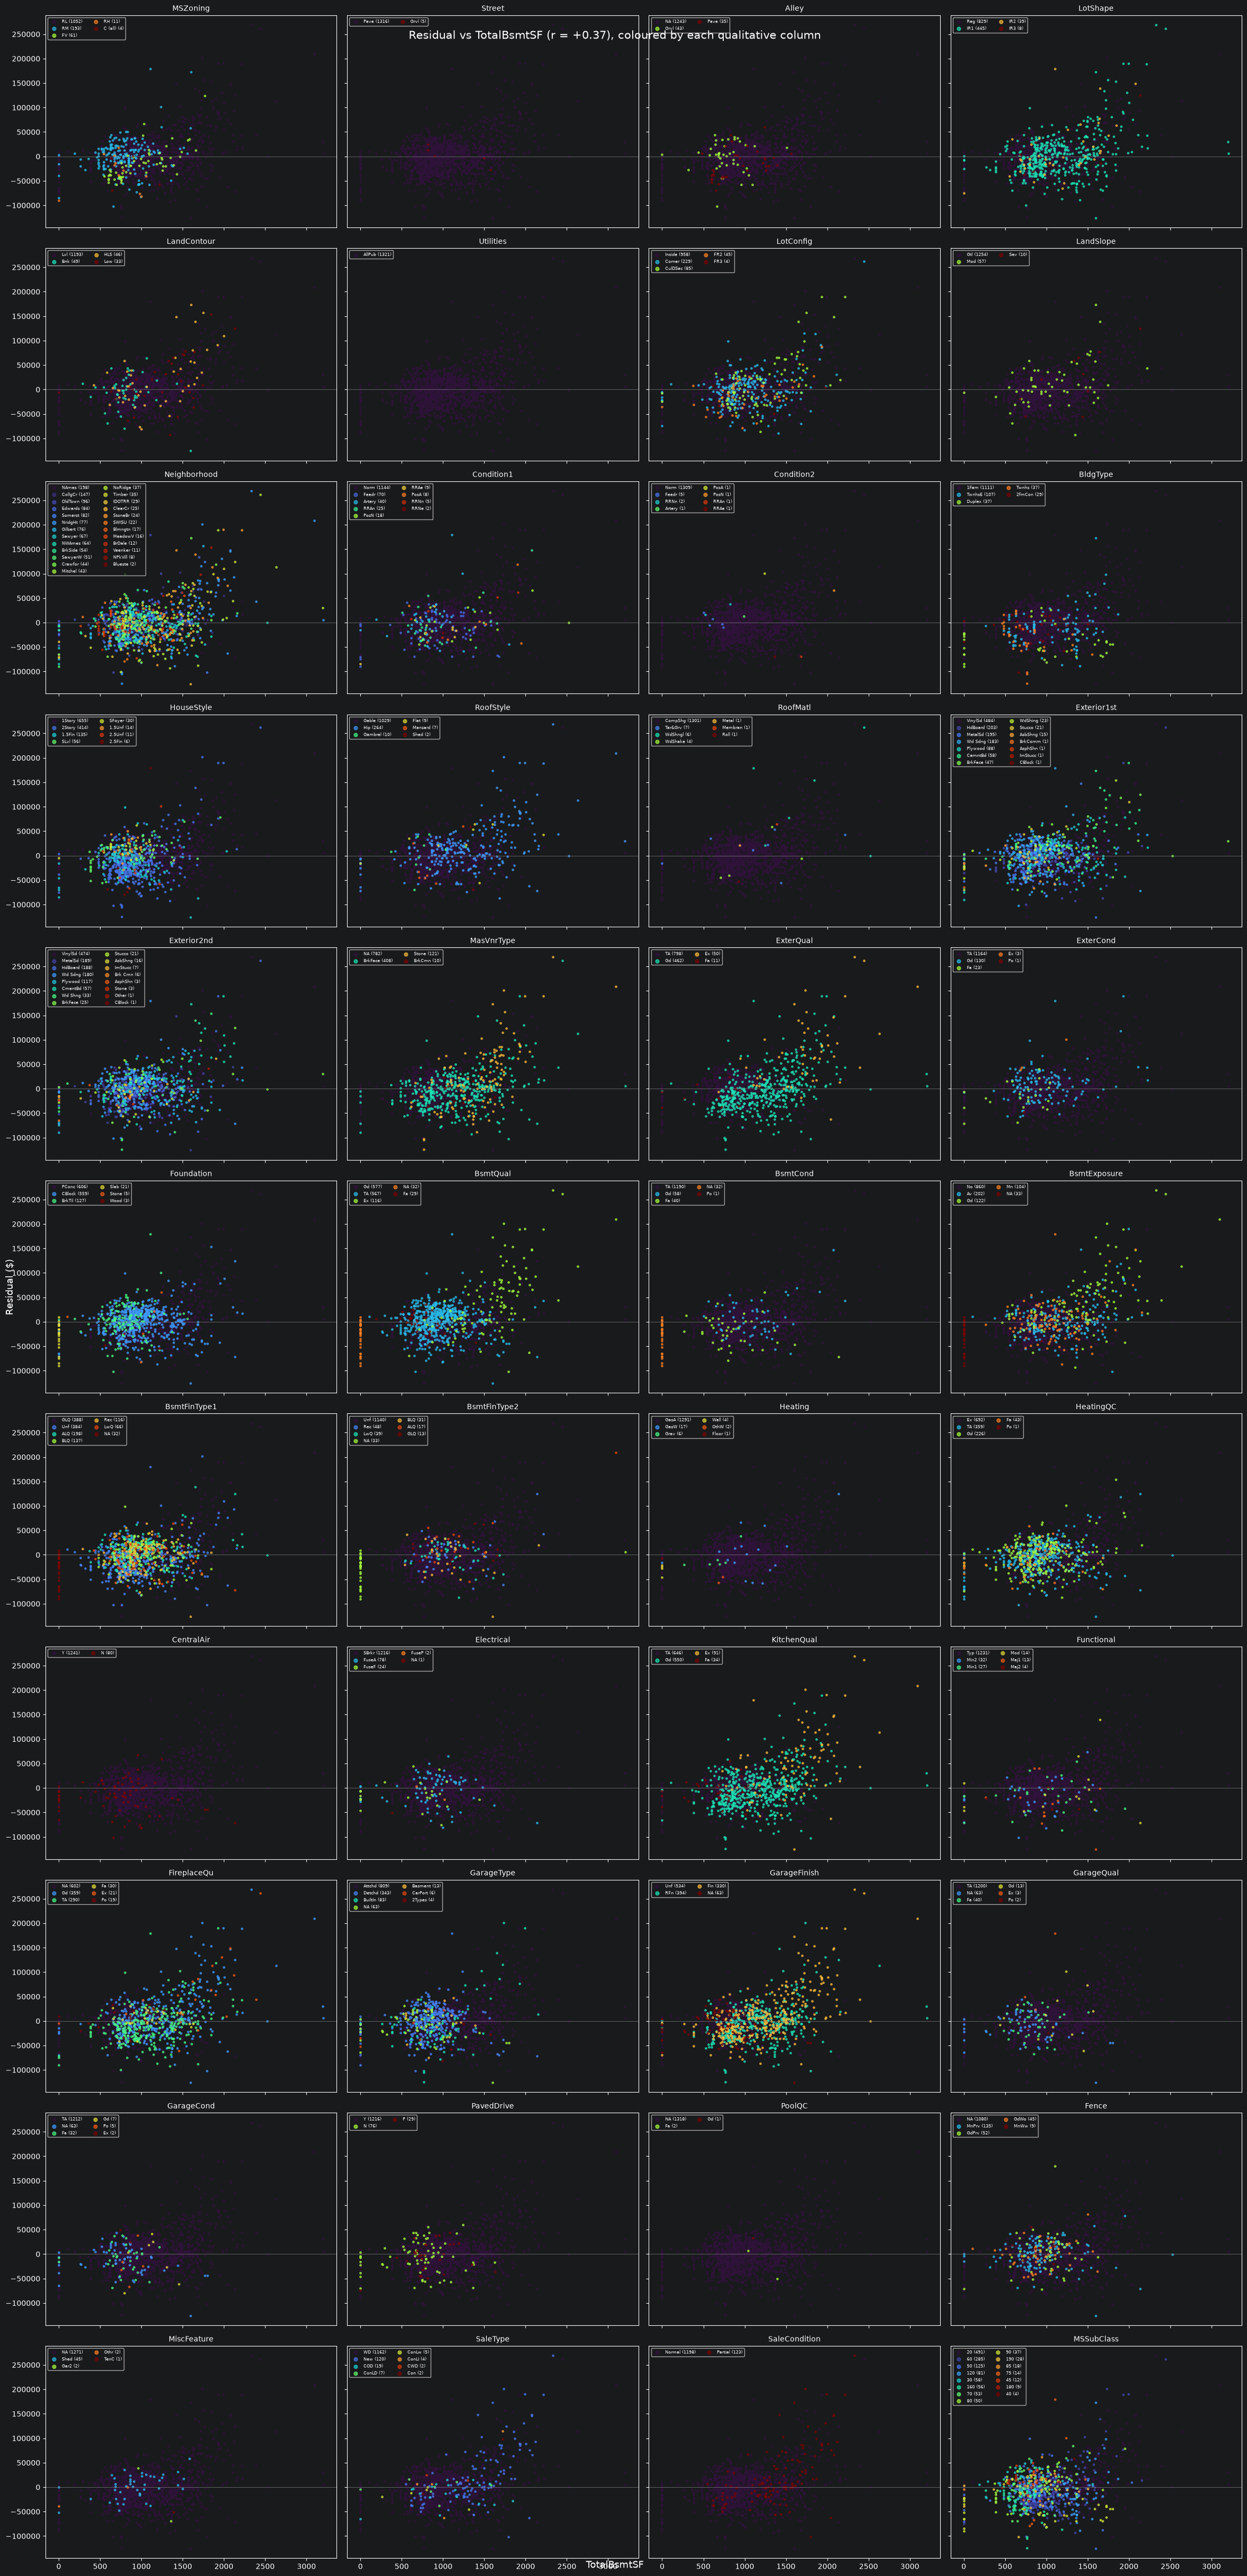

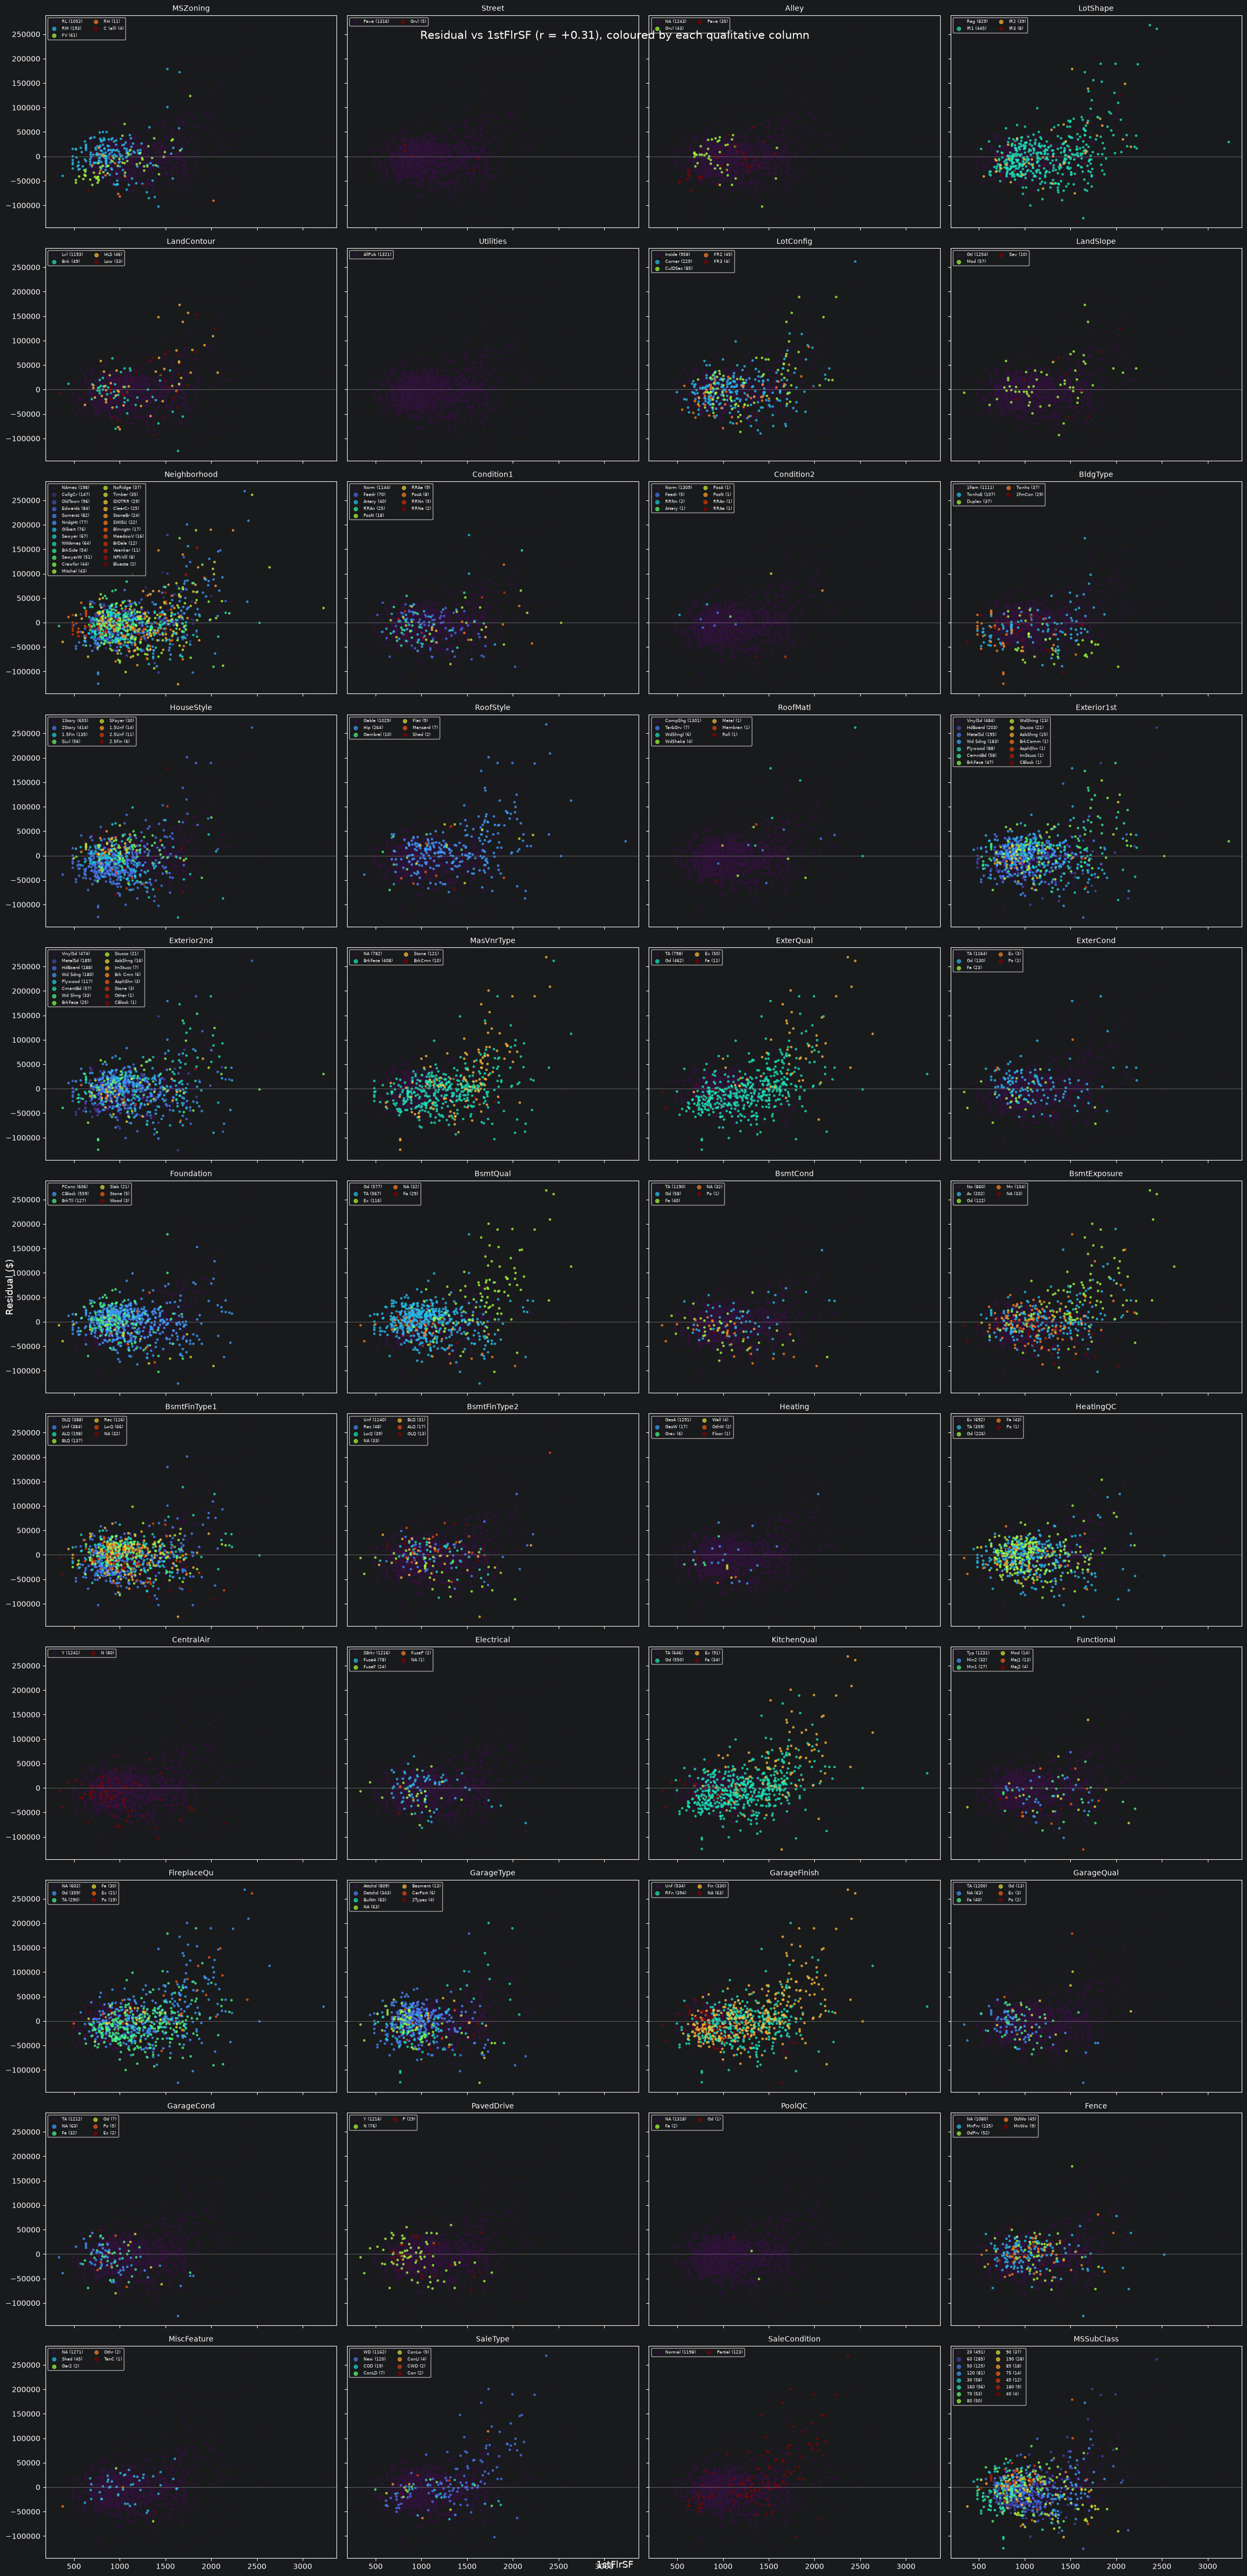

In [23]:
# --- Correlation of every numeric column with the residual ---
exclude = {"Id", "SalePrice", "Predicted", "Residual", "Resid_σ", "MSSubClass"}
num_cols = [c for c in out.select_dtypes("number").columns if c not in exclude]
corr = out[num_cols].corrwith(out["Residual"]).dropna()
ranked = corr.reindex(corr.abs().sort_values(ascending=False).index)
print("Top 10 correlations with the residual:")
print(ranked.head(10).round(3))
top3 = ranked.index[:3]

# --- Every qualitative column (MSSubClass included: its numbers are codes) ---
qual_cols = list(out.select_dtypes(exclude="number").columns) + ["MSSubClass"]
print(f"\n{len(qual_cols)} qualitative columns")

def plot_coloured_grid(feature, ncols=4):
    nrows = int(np.ceil(len(qual_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(24, 4.5 * nrows), sharex=True, sharey=True)
    for ax, cat in zip(axes.flat, qual_cols):
        labels = out[cat].fillna("NA").astype(str)
        levels = labels.value_counts().index                 # most common category first
        colours = plt.cm.turbo(np.linspace(0, 1, len(levels)))
        for level, colour in zip(levels, colours):
            mask = labels == level
            ax.scatter(out.loc[mask, feature], out.loc[mask, "Residual"], color=colour,
                       s=6, alpha=0.7, label=f"{level} ({mask.sum()})")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(cat, fontsize=10)
        ax.legend(fontsize=6, ncol=2, loc="upper left", markerscale=2)
    for ax in axes.flat[len(qual_cols):]:
        ax.axis("off")
    fig.supxlabel(feature, fontsize=13)
    fig.supylabel("Residual ($)", fontsize=13)
    fig.suptitle(f"Residual vs {feature} (r = {corr[feature]:+.2f}), coloured by each qualitative column",
                 fontsize=15)
    plt.tight_layout(); plt.show()

for feature in top3:
    plot_coloured_grid(feature)

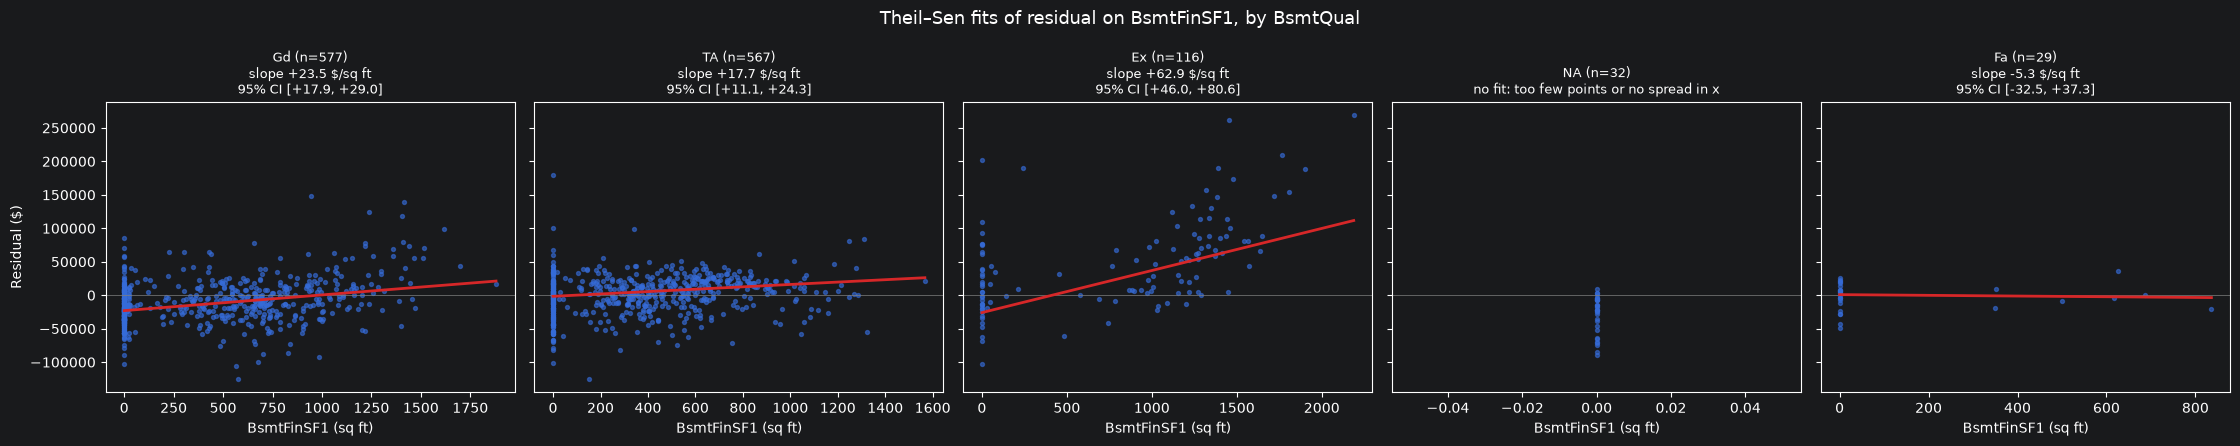

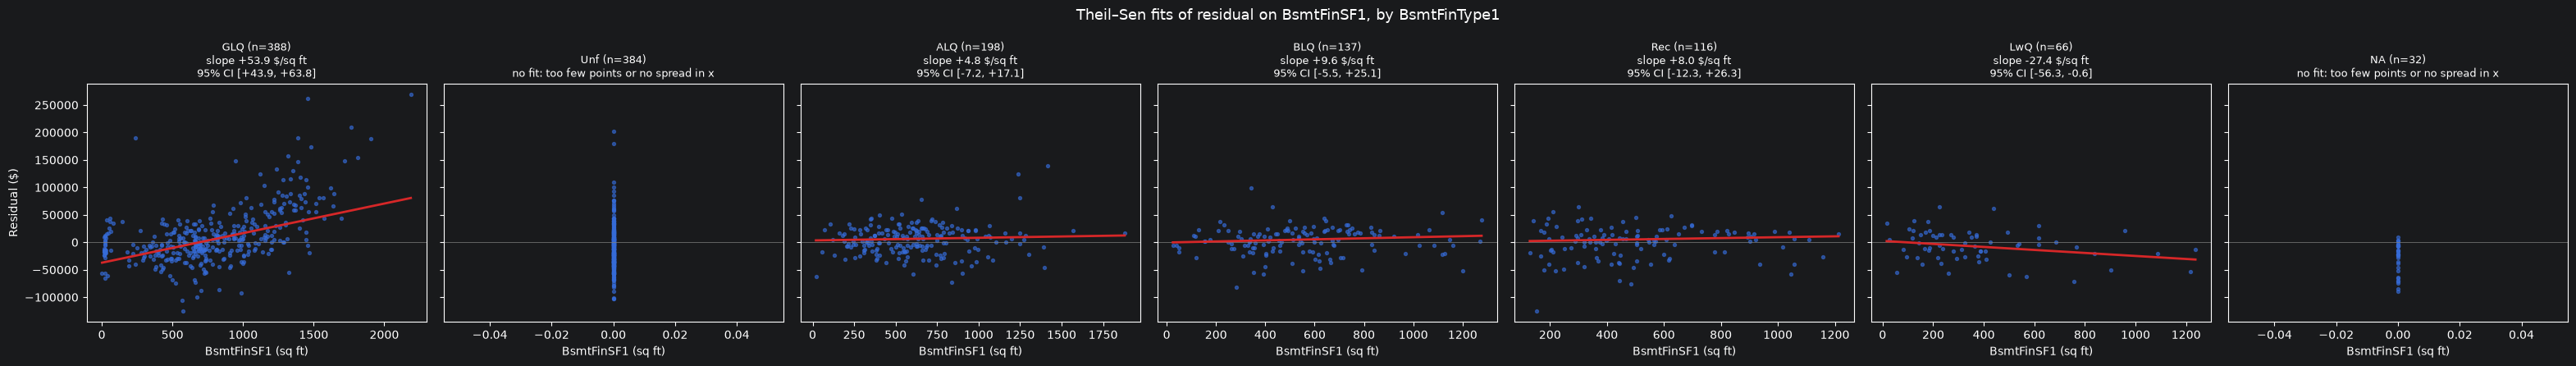

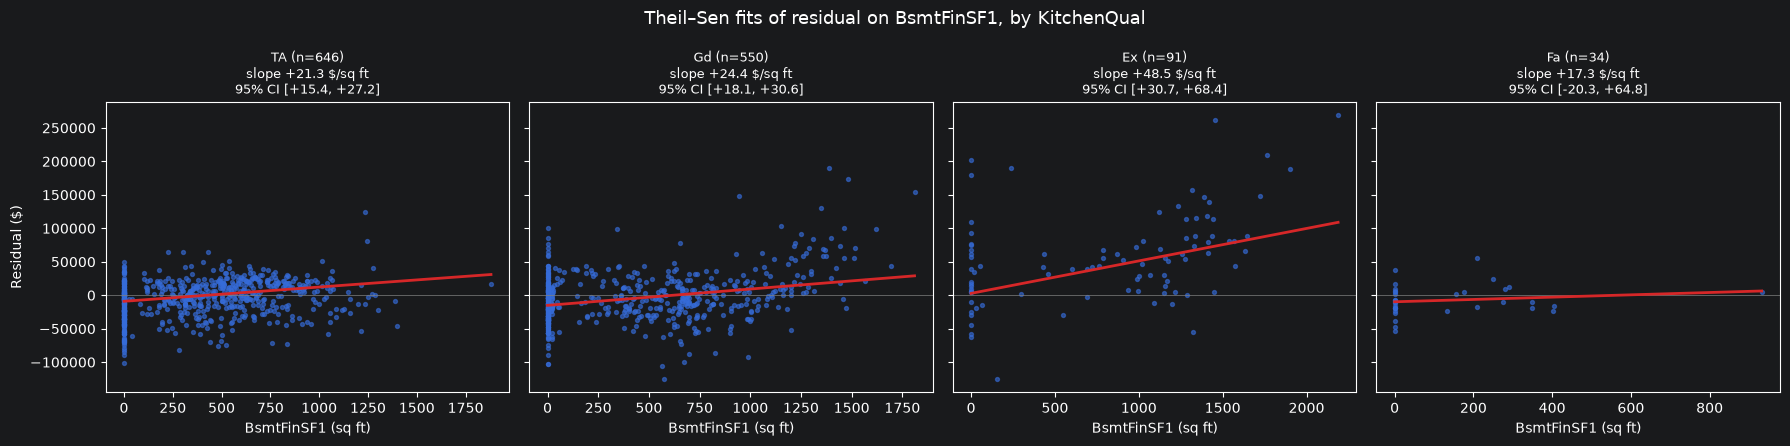

,column,level,n,slope,CI low,CI high
0,BsmtQual,Gd,577,23.5,17.9,29.0
1,BsmtQual,TA,567,17.7,11.1,24.3
2,BsmtQual,Ex,116,62.9,46.0,80.6
3,BsmtQual,Fa,29,-5.3,-32.5,37.3
4,BsmtFinType1,GLQ,388,53.9,43.9,63.8
5,BsmtFinType1,ALQ,198,4.8,-7.2,17.1
6,BsmtFinType1,BLQ,137,9.6,-5.5,25.1
7,BsmtFinType1,Rec,116,8.0,-12.3,26.3
8,BsmtFinType1,LwQ,66,-27.4,-56.3,-0.6
9,KitchenQual,TA,646,21.3,15.4,27.2


In [24]:
from scipy.stats import theilslopes

group_cols = ["BsmtQual", "BsmtFinType1", "KitchenQual"]
rows = []

for col in group_cols:
    labels = out[col].fillna("NA").astype(str)
    levels = labels.value_counts().index
    ncols = len(levels)
    fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, level in zip(axes, levels):
        g = out[labels == level]
        x = g["BsmtFinSF1"].values.astype(float)
        y = g["Residual"].values.astype(float)
        ax.scatter(x, y, s=8, alpha=0.6)
        ax.axhline(0, color="grey", lw=0.5)

        if len(g) >= 3 and np.ptp(x) > 0:              # need ≥3 points and some spread in x
            slope, intercept, lo, hi = theilslopes(y, x)
            xs = np.linspace(x.min(), x.max(), 100)
            ax.plot(xs, intercept + slope * xs, color="tab:red", lw=2)
            ax.set_title(f"{level} (n={len(g)})\nslope {slope:+.1f} $/sq ft\n95% CI [{lo:+.1f}, {hi:+.1f}]",
                         fontsize=9)
            rows.append({"column": col, "level": level, "n": len(g),
                         "slope": slope, "CI low": lo, "CI high": hi})
        else:
            ax.set_title(f"{level} (n={len(g)})\nno fit: too few points or no spread in x", fontsize=9)
        ax.set_xlabel("BsmtFinSF1 (sq ft)")

    axes[0].set_ylabel("Residual ($)")
    fig.suptitle(f"Theil–Sen fits of residual on BsmtFinSF1, by {col}", fontsize=13)
    plt.tight_layout(); plt.show()

pd.DataFrame(rows).round(1)

Removed 416 houses with BsmtFinSF1 = 0; 905 remain


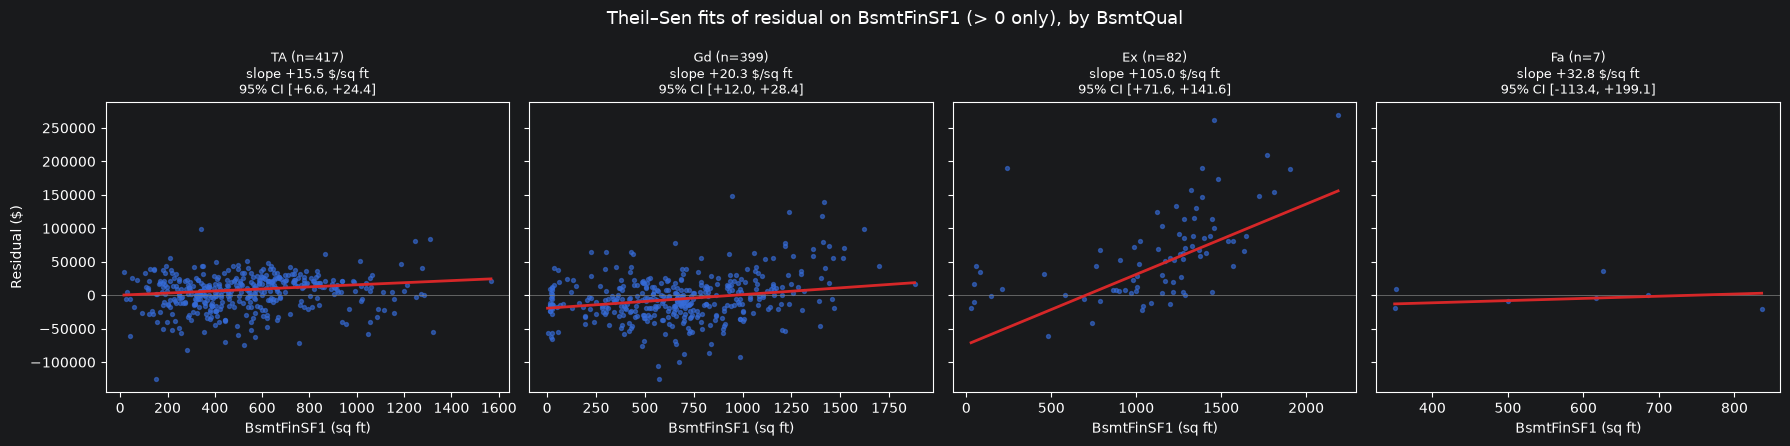

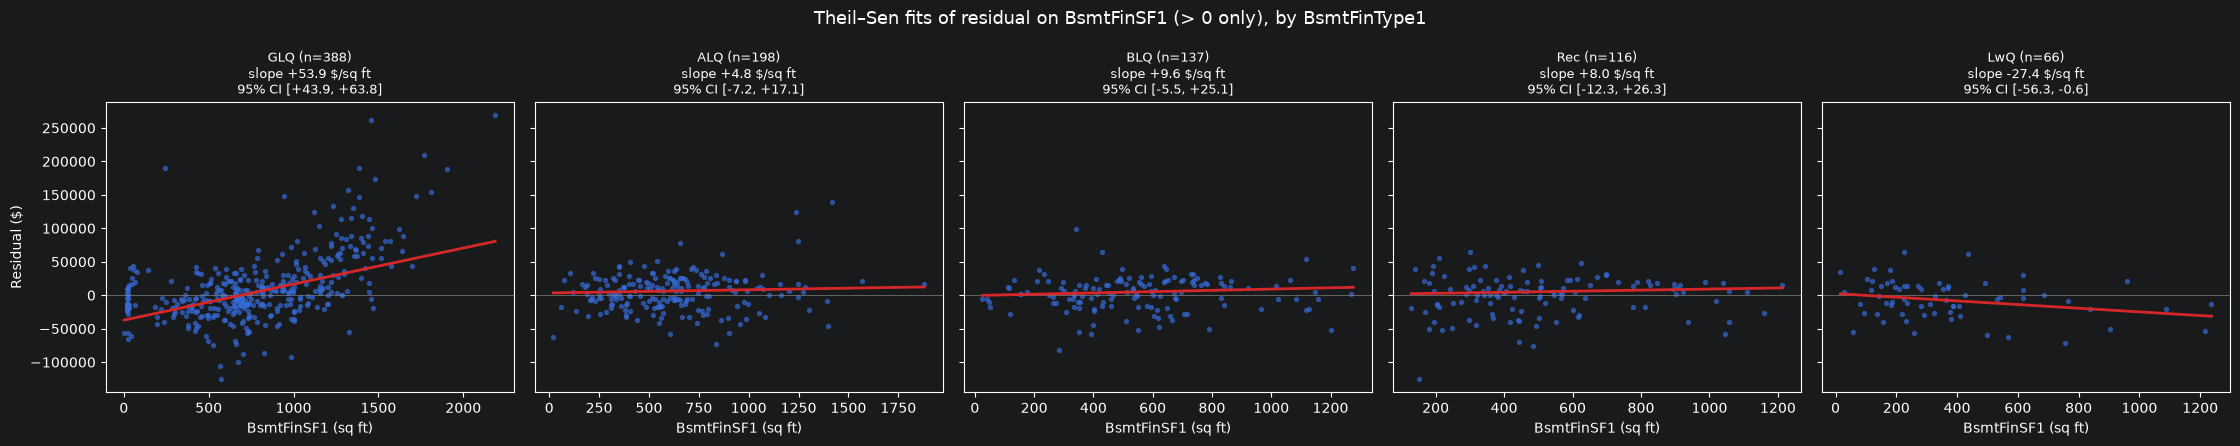

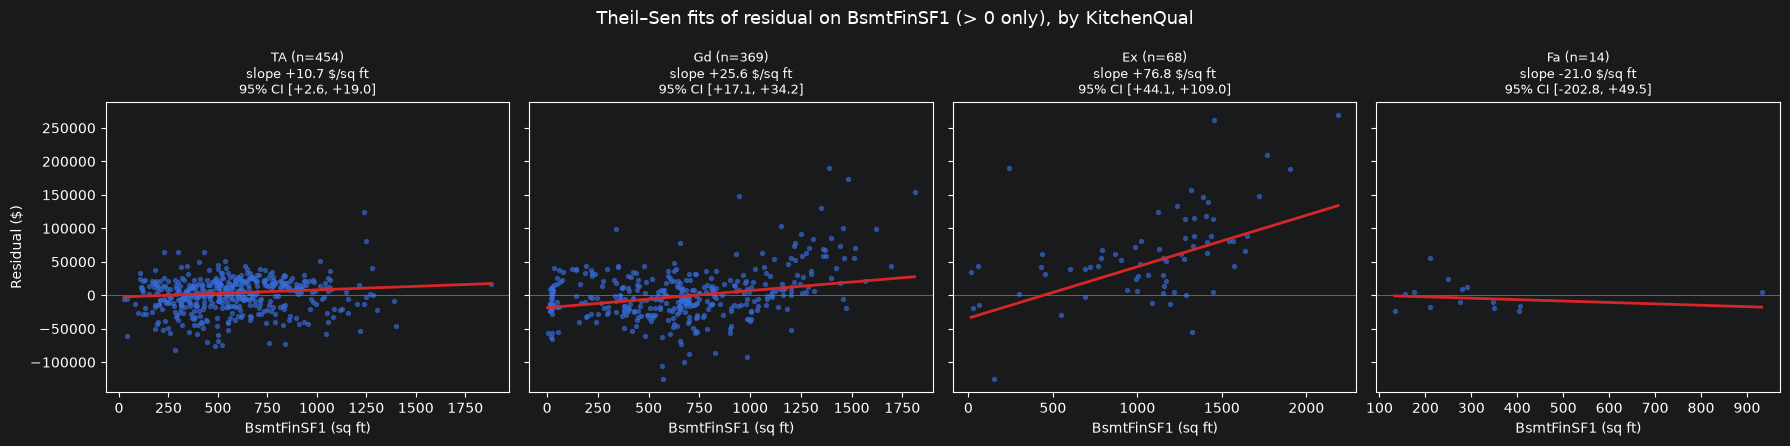

,column,level,n,slope,CI low,CI high
0,BsmtQual,TA,417,15.5,6.6,24.4
1,BsmtQual,Gd,399,20.3,12.0,28.4
2,BsmtQual,Ex,82,105.0,71.6,141.6
3,BsmtQual,Fa,7,32.8,-113.4,199.1
4,BsmtFinType1,GLQ,388,53.9,43.9,63.8
5,BsmtFinType1,ALQ,198,4.8,-7.2,17.1
6,BsmtFinType1,BLQ,137,9.6,-5.5,25.1
7,BsmtFinType1,Rec,116,8.0,-12.3,26.3
8,BsmtFinType1,LwQ,66,-27.4,-56.3,-0.6
9,KitchenQual,TA,454,10.7,2.6,19.0


In [25]:
from scipy.stats import theilslopes

has_fin = out[out["BsmtFinSF1"] > 0]
print(f"Removed {len(out) - len(has_fin)} houses with BsmtFinSF1 = 0; {len(has_fin)} remain")

group_cols = ["BsmtQual", "BsmtFinType1", "KitchenQual"]
rows = []

for col in group_cols:
    labels = has_fin[col].fillna("NA").astype(str)
    levels = labels.value_counts().index
    ncols = len(levels)
    fig, axes = plt.subplots(1, ncols, figsize=(4.5 * ncols, 4.5), sharey=True)
    axes = np.atleast_1d(axes)

    for ax, level in zip(axes, levels):
        g = has_fin[labels == level]
        x = g["BsmtFinSF1"].values.astype(float)
        y = g["Residual"].values.astype(float)
        ax.scatter(x, y, s=8, alpha=0.6)
        ax.axhline(0, color="grey", lw=0.5)

        if len(g) >= 3 and np.ptp(x) > 0:
            slope, intercept, lo, hi = theilslopes(y, x)
            xs = np.linspace(x.min(), x.max(), 100)
            ax.plot(xs, intercept + slope * xs, color="tab:red", lw=2)
            ax.set_title(f"{level} (n={len(g)})\nslope {slope:+.1f} $/sq ft\n95% CI [{lo:+.1f}, {hi:+.1f}]",
                         fontsize=9)
            rows.append({"column": col, "level": level, "n": len(g),
                         "slope": slope, "CI low": lo, "CI high": hi})
        else:
            ax.set_title(f"{level} (n={len(g)})\nno fit: too few points or no spread in x", fontsize=9)
        ax.set_xlabel("BsmtFinSF1 (sq ft)")

    axes[0].set_ylabel("Residual ($)")
    fig.suptitle(f"Theil–Sen fits of residual on BsmtFinSF1 (> 0 only), by {col}", fontsize=13)
    plt.tight_layout(); plt.show()

pd.DataFrame(rows).round(1)